# Trabajo final · Análisis de datos de corteza piriforme

Datos: registros extracelulares de neuronas de corteza piriforme (PCx) de un ratón en la tarea
olor–contexto–recompensa de **Federman, Romano et al. (2024, Nature Communications)**. Los datos ya vienen
con spike sorting: para cada spike tenemos la neurona, el tiempo y la información del ensayo.

Este notebook genera **todas las figuras de la presentación** (carpeta `figuras/`). Corre de punta a punta.

| Parte | Contenido |
|---|---|
| 0 | Carga de datos, tabla de ensayos y control de calidad de neuronas |
| I | Perfiles de respuesta: raster + PSTH por neurona, 4 alineaciones; clasificación de respuestas |
| II | Actividad poblacional por tipo de ensayo |
| III | Correlación neuronal: autocorrelogramas y cross-correlogramas |
| IV | Análisis libre: ¿el contexto recompensado cambia la coordinación? (IV.1–IV.2 hechos; IV.3–IV.6 en el handoff) |

**Convención de colores** (la de la consigna): OR·CR rojo, OR·CU naranja, OU·CR negro, OU·CU gris.
Los ensayos sin olor (sólo contexto) van en azul (CR) y celeste (CU).

In [1]:
from pathlib import Path
import warnings

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyArrowPatch
from scipy import fft as sfft
from scipy import stats
from scipy.ndimage import gaussian_filter1d

warnings.filterwarnings("ignore", category=RuntimeWarning)

BASE = Path.cwd()
DATA = BASE / "MatrizFinal_8col.csv"
FIG = BASE / "figuras"
for sub in ["parte0", "parte1", "parte1/neuronas", "parte2", "parte3", "parte4"]:
    (FIG / sub).mkdir(parents=True, exist_ok=True)

RNG = np.random.default_rng(2026)

# Paleta tomada de la presentación (tinta, gris, azul de acento, celeste de tarjetas)
TINTA, GRIS, ACENTO, CLARO = "#262425", "#666666", "#4A86E8", "#E6EEFC"
mpl.rcParams.update({
    "font.family": "Arial", "font.size": 10, "axes.titlesize": 10.5, "axes.labelsize": 10,
    "axes.edgecolor": TINTA, "axes.labelcolor": TINTA, "xtick.color": TINTA, "ytick.color": TINTA,
    "text.color": TINTA, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.facecolor": "white",
})

COLORES = {1: "#D62728", 2: "#FF8C1A", 3: "#111111", 4: "#9E9E9E", 5: ACENTO, 6: "#A9C4F5"}
ETIQ = {1: "OR·CR", 2: "OR·CU", 3: "OU·CR", 4: "OU·CU", 5: "CR sin olor", 6: "CU sin olor"}


def guardar(fig, nombre, cerrar=False):
    fig.savefig(FIG / nombre)
    if cerrar:
        plt.close(fig)

## Parte 0 · Datos y control de calidad

Cada fila del CSV es un spike: `neurona, t, ensayo, t_entrada, t_salida, t_inhal, tipo, t_inicio`.
Los tiempos son **absolutos** (segundos desde el comienzo de la sesión), así que los ensayos son tramos contiguos de
una única sesión continua. Eso permite calcular correlogramas sobre toda la sesión.

In [2]:
raw = pd.read_csv(DATA, header=None,
                  names=["neurona", "t", "ensayo", "t_entrada", "t_salida", "t_inhal", "tipo", "t_inicio"])
T_SESION = raw.t.max()

trials = (raw.groupby("ensayo")[["t_inicio", "t_entrada", "t_salida", "t_inhal", "tipo"]].first()
          .astype({"tipo": int}))
trials["dur_contexto"] = trials.t_salida - trials.t_entrada        # proxy de la velocidad del animal
trials["lat_inhal"] = trials.t_inhal - trials.t_entrada           # entrada -> primera inhalación del olor
trials["anomalo"] = trials.lat_inhal < 0                          # inhalación antes de entrar: se excluye
spikes = {int(n): np.sort(g.t.values) for n, g in raw.groupby("neurona")}
NEURONAS = sorted(spikes)

print(f"{len(raw):,} spikes · {len(NEURONAS)} neuronas · {len(trials)} ensayos · sesión de {T_SESION/60:.1f} min")
print(trials.tipo.map(ETIQ).value_counts().reindex(ETIQ.values()).to_string())
print("Ensayos anómalos (inhalación antes de la entrada):", list(trials.index[trials.anomalo]))
print(trials[["dur_contexto", "lat_inhal"]].describe().round(2).to_string())

982,912 spikes · 64 neuronas · 176 ensayos · sesión de 64.9 min
tipo
OR·CR          63
OR·CU          31
OU·CR          24
OU·CU          33
CR sin olor    13
CU sin olor    12
Ensayos anómalos (inhalación antes de la entrada): [144]
       dur_contexto  lat_inhal
count        176.00     151.00
mean           3.87       0.40
std            5.13       0.11
min            0.64      -0.53
25%            0.99       0.35
50%            2.10       0.39
75%            3.05       0.44
max           34.88       0.90


**Control de calidad por neurona.** Calculamos la tasa media, la fracción de ensayos en los que la neurona dispara
(si se "pierde" a mitad de sesión, el spike sorting no la siguió) y el % de intervalos entre spikes (ISI) < 2 ms,
que una sola neurona no puede producir por el período refractario (si es alto, la unidad puede ser multi-unidad).

Criterio de **neurona estable** para análisis poblacionales y de correlación: tasa ≥ 0,5 Hz y presente en ≥ 90 % de
los ensayos. Las demás se grafican en la Parte I pero no entran en los promedios ni en los pares.

In [3]:
pres = raw.groupby("neurona").ensayo.nunique()
neur = pd.DataFrame(index=pd.Index(NEURONAS, name="neurona"))
neur["n_spikes"] = [len(spikes[n]) for n in NEURONAS]
neur["tasa_hz"] = neur.n_spikes / T_SESION
neur["frac_ensayos"] = pres.reindex(NEURONAS).values / len(trials)
neur["isi_viol_pct"] = [100 * np.mean(np.diff(spikes[n]) < 0.002) for n in NEURONAS]
neur["estable"] = (neur.tasa_hz >= 0.5) & (neur.frac_ensayos >= 0.9)
ESTABLES = list(neur.index[neur.estable])
print(f"Neuronas estables: {len(ESTABLES)} de {len(NEURONAS)}  ->  {len(ESTABLES)*(len(ESTABLES)-1)//2} pares")
print(f"ISI<2ms en estables: mediana {neur.loc[ESTABLES,'isi_viol_pct'].median():.2f} %, "
      f"máx {neur.loc[ESTABLES,'isi_viol_pct'].max():.2f} %")

# Tasa por ensayo (para ver estabilidad a lo largo de la sesión)
inicio, fin = trials.t_inicio.values, np.r_[trials.t_inicio.values[1:], T_SESION]
tasa_ensayo = np.array([(np.searchsorted(spikes[n], fin) - np.searchsorted(spikes[n], inicio)) / (fin - inicio)
                        for n in NEURONAS])

Neuronas estables: 44 de 64  ->  946 pares
ISI<2ms en estables: mediana 0.25 %, máx 2.19 %


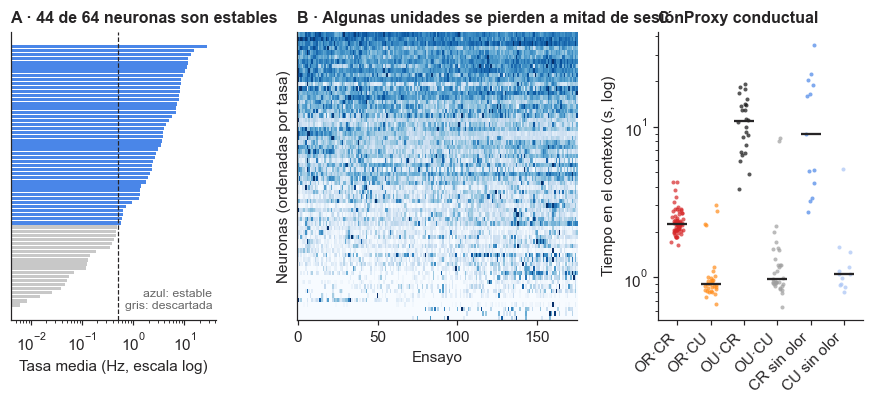

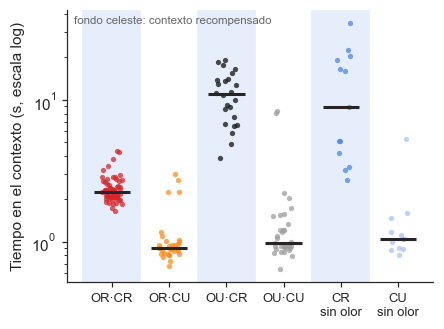

Mediana del tiempo en el contexto por tipo (s):
tipo
CR sin olor     8.92
CU sin olor     1.05
OR·CR           2.25
OR·CU           0.90
OU·CR          10.90
OU·CU           0.98


In [4]:
fig = plt.figure(figsize=(10, 3.4))
gs = fig.add_gridspec(1, 3, width_ratios=[1.1, 1.5, 1.1], wspace=0.35)

ax = fig.add_subplot(gs[0])
orden = neur.sort_values("tasa_hz").index
ax.barh(range(len(orden)), neur.loc[orden, "tasa_hz"],
        color=[ACENTO if neur.loc[n, "estable"] else "#C8C8C8" for n in orden], height=0.8)
ax.set_xscale("log"); ax.set_yticks([]); ax.set_xlabel("Tasa media (Hz, escala log)")
ax.axvline(0.5, color=TINTA, lw=0.8, ls="--")
ax.set_title(f"A · {len(ESTABLES)} de {len(NEURONAS)} neuronas son estables")
ax.text(0.98, 0.04, "azul: estable\ngris: descartada", transform=ax.transAxes, ha="right", fontsize=8, color=GRIS)

ax = fig.add_subplot(gs[1])
norm = tasa_ensayo[[NEURONAS.index(n) for n in orden]]
norm = norm / np.maximum(norm.max(1, keepdims=True), 1e-9)
ax.imshow(norm, aspect="auto", cmap="Blues", interpolation="nearest", origin="lower")
ax.set_xlabel("Ensayo"); ax.set_ylabel("Neuronas (ordenadas por tasa)"); ax.set_yticks([])
ax.set_title("B · Algunas unidades se pierden a mitad de sesión")

ax = fig.add_subplot(gs[2])
for k in [1, 2, 3, 4, 5, 6]:
    d = trials.loc[trials.tipo == k, "dur_contexto"]
    x = k + RNG.uniform(-0.18, 0.18, len(d))
    ax.scatter(x, d, s=7, color=COLORES[k], alpha=0.7, lw=0)
    ax.hlines(d.median(), k - 0.3, k + 0.3, color=TINTA, lw=1.5)
ax.set_yscale("log"); ax.set_xticks(range(1, 7)); ax.set_xticklabels([ETIQ[k] for k in range(1, 7)], rotation=45, ha="right")
ax.set_ylabel("Tiempo en el contexto (s, log)")
ax.set_title("C · Proxy conductual")
guardar(fig, "parte0/control_calidad.png")
plt.show()

# Versión grande del proxy conductual para la diapositiva
fig, ax = plt.subplots(figsize=(4.3, 3.2))
for k in [1, 2, 3, 4, 5, 6]:
    d = trials.loc[trials.tipo == k, "dur_contexto"]
    ax.scatter(k + RNG.uniform(-0.18, 0.18, len(d)), d, s=12, color=COLORES[k], alpha=0.75, lw=0)
    ax.hlines(d.median(), k - 0.32, k + 0.32, color=TINTA, lw=2)
ax.set_yscale("log"); ax.set_xticks(range(1, 7))
ax.set_xticklabels([ETIQ[k].replace(" sin olor", "\nsin olor") for k in range(1, 7)], fontsize=8.5)
ax.set_ylabel("Tiempo en el contexto (s, escala log)")
ax.axvspan(0.5, 1.5, color=CLARO, zorder=0); ax.axvspan(2.5, 3.5, color=CLARO, zorder=0); ax.axvspan(4.5, 5.5, color=CLARO, zorder=0)
ax.text(0.02, 0.98, "fondo celeste: contexto recompensado", transform=ax.transAxes, fontsize=7.5, color=GRIS, va="top")
guardar(fig, "parte0/comportamiento.png")
plt.show()

print("Mediana del tiempo en el contexto por tipo (s):")
print(trials.groupby(trials.tipo.map(ETIQ)).dur_contexto.median().round(2).to_string())

## Utilidades: alinear spikes a eventos, conteos y PSTH

- `alinear`: para cada evento, los tiempos de spike relativos a él dentro de una ventana.
- `conteos`: matriz ensayos × bins.
- `psth`: tasa promedio (Hz) suavizada con un núcleo gaussiano (σ = 30 ms por defecto).

Alineaciones pedidas: inicio del ensayo, entrada al contexto, primera inhalación del olor y salida del contexto.
La alineación a la inhalación sólo existe para los tipos 1–4 (los tipos 5–6 no tienen olor).

In [5]:
ALIN = {
    "inicio": ("t_inicio", (-1.0, 4.0), "Inicio del ensayo"),
    "entrada": ("t_entrada", (-2.0, 3.0), "Entrada al contexto"),
    "inhalacion": ("t_inhal", (-2.0, 3.0), "Primera inhalación del olor"),
    "salida": ("t_salida", (-2.0, 3.0), "Salida del contexto"),
}
TIPOS_OLOR = [1, 2, 3, 4]
VALIDOS = trials[~trials.anomalo]


def alinear(spk, eventos, ventana):
    lo = np.searchsorted(spk, eventos + ventana[0])
    hi = np.searchsorted(spk, eventos + ventana[1])
    return [spk[a:b] - e for a, b, e in zip(lo, hi, eventos)]


def conteos(spk, eventos, ventana, ancho):
    edges = np.arange(ventana[0], ventana[1] + ancho / 2, ancho)
    rel = alinear(spk, eventos, ventana)
    return np.array([np.histogram(r, edges)[0] for r in rel]), edges


def psth(spk, eventos, ventana, ancho=0.01, sigma=0.03):
    C, edges = conteos(spk, eventos, ventana, ancho)
    r = C.mean(0) / ancho
    return gaussian_filter1d(r, sigma / ancho), edges[:-1] + ancho / 2


def ensayos_para(alin, tipos=(1, 2, 3, 4, 5, 6)):
    tr = VALIDOS[VALIDOS.tipo.isin(tipos)]
    if alin == "inhalacion":
        tr = tr[tr.tipo.isin(TIPOS_OLOR)]
    return tr.sort_values(["tipo"], kind="stable")


def tasa_ventana(spk, eventos, a, b):
    return (np.searchsorted(spk, eventos + b) - np.searchsorted(spk, eventos + a)) / (b - a)

## Parte I · Perfiles de respuesta neuronal

Para cada neurona: raster (cada fila un ensayo, agrupados por tipo y coloreados) y PSTH por tipo de ensayo, con las
cuatro alineaciones. En el raster alineado a la entrada marcamos con un punto la salida de cada ensayo: el tiempo en el
contexto varía mucho entre ensayos porque depende de la velocidad del animal.

Se exportan las 64 neuronas a `figuras/parte1/neuronas/`.

In [6]:
def fig_neurona(nid, alineaciones=tuple(ALIN), figsize=None, titulo=True):
    n = len(alineaciones)
    fig, axs = plt.subplots(2, n, figsize=figsize or (3.2 * n, 4.8), sharex="col",
                            gridspec_kw=dict(height_ratios=[1.5, 1], hspace=0.08, wspace=0.28), squeeze=False)
    for j, alin in enumerate(alineaciones):
        col, ven, nombre = ALIN[alin]
        tr = ensayos_para(alin)
        ev = tr[col].values
        rel = alinear(spikes[nid], ev, ven)
        ax = axs[0, j]
        fila, y0 = np.zeros(len(tr)), 0
        for k in sorted(tr.tipo.unique()):
            idx = np.where(tr.tipo.values == k)[0]
            fila[idx] = y0 + np.arange(len(idx))
            xs = np.concatenate([rel[i] for i in idx]) if len(idx) else np.array([])
            ys = np.concatenate([np.full(len(rel[i]), fila[i]) for i in idx]) if len(idx) else np.array([])
            ax.scatter(xs, ys, marker="|", s=3, lw=0.45, color=COLORES[k], rasterized=True)
            y0 += len(idx) + 4
        if alin == "entrada":
            sal = tr.t_salida.values - ev
            m = sal < ven[1]
            ax.scatter(sal[m], fila[m], s=2.5, color=ACENTO, zorder=3, lw=0)
        ax.axvline(0, color=TINTA, lw=0.7, ls="--")
        ax.set_ylim(-2, y0); ax.set_yticks([])
        ax.set_title(nombre, fontsize=9)
        ax.spines["left"].set_visible(False)
        ax2 = axs[1, j]
        for k in sorted(tr.tipo.unique()):
            r, tc = psth(spikes[nid], tr.loc[tr.tipo == k, col].values, ven)
            ax2.plot(tc, r, color=COLORES[k], lw=1.2 if k <= 4 else 0.9, ls="-" if k <= 4 else "--", label=ETIQ[k])
        ax2.axvline(0, color=TINTA, lw=0.7, ls="--")
        ax2.set_xlabel("Tiempo (s)")
        if j == 0:
            ax2.set_ylabel("Tasa (Hz)")
            axs[0, 0].set_ylabel("Ensayos por tipo")
    axs[1, -1].legend(fontsize=7, loc="upper right", ncol=1, handlelength=1.5)
    if titulo:
        fig.suptitle(f"Neurona {nid} · {neur.loc[nid, 'tasa_hz']:.1f} Hz" +
                     ("" if neur.loc[nid, "estable"] else " · (no estable)"), x=0.01, ha="left", fontweight="bold")
    return fig


for nid in NEURONAS:
    f = fig_neurona(nid)
    f.savefig(FIG / f"parte1/neuronas/neurona_{nid:02d}.png", dpi=150)
    plt.close(f)
print("Exportadas", len(NEURONAS), "figuras de neuronas")

Exportadas 64 figuras de neuronas


### Clasificación de respuestas

Ventanas (justificación):
- **Línea de base**: 0,5–2 s después del inicio del ensayo. El animal ya corre por el corredor, lejos del contexto, y
  no se mezcla con la ventana de respuesta/recompensa del ensayo anterior.
- **Contexto (anticipación)**: de −0,5 a +0,3 s respecto de la entrada. El contexto ya es visible y el olor todavía no
  se inhaló (la primera inhalación llega ≥ 0,32 s después de entrar).
- **Olor**: 0–1 s después de la primera inhalación (dura lo que el pulso de olor).
- **Salida / recompensa**: 0–1,5 s después de salir del contexto (ventana de respuesta: lamidos y agua en OR·CR).

Tests (por neurona, α = 0,01):
1. **Responde al olor**: Wilcoxon pareado, tasa en la ventana de olor vs línea de base del mismo ensayo → excitada o inhibida.
2. **Selectiva al olor**: Mann–Whitney, OR (tipos 1, 2) vs OU (3, 4) en la ventana de olor.
3. **Selectiva al contexto**: Mann–Whitney, CR (1, 3, 5) vs CU (2, 4, 6) en la ventana de anticipación.
4. **Selectiva a la recompensa**: Mann–Whitney, OR·CR vs OU·CR en la ventana de salida. Comparamos sólo dentro del
   contexto recompensado porque en el contexto no recompensado el ratón sale a los ~0,9 s y la ventana de salida
   todavía contiene la respuesta al olor; en OR·CR y OU·CR la salida llega cuando esa respuesta ya terminó.

Con ~45 neuronas y α = 0,01 esperamos < 1 falso positivo por test. Ojo: la selectividad al contexto puede estar
confundida con la velocidad (en el contexto recompensado el ratón se frena; ver Parte 0).

In [7]:
VEN = {"base": ("t_inicio", 0.5, 2.0), "contexto": ("t_entrada", -0.5, 0.3),
       "olor": ("t_inhal", 0.0, 1.0), "salida": ("t_salida", 0.0, 1.5)}
ALFA = 0.01
tr_olor = VALIDOS[VALIDOS.tipo.isin(TIPOS_OLOR)]


def clasificar(nid):
    s = spikes[nid]
    out = {}
    b = tasa_ventana(s, tr_olor.t_inicio.values, 0.5, 2.0)
    o = tasa_ventana(s, tr_olor.t_inhal.values, 0.0, 1.0)
    try:
        p = stats.wilcoxon(o, b).pvalue
    except ValueError:
        p = 1.0
    out["resp_olor"] = ("excitada" if o.mean() > b.mean() else "inhibida") if p < ALFA else "sin respuesta"
    out["d_olor_hz"] = o.mean() - b.mean()
    ty = tr_olor.tipo.values
    out["sel_olor"] = stats.mannwhitneyu(o[np.isin(ty, [1, 2])], o[np.isin(ty, [3, 4])]).pvalue < ALFA
    c = tasa_ventana(s, VALIDOS.t_entrada.values, -0.5, 0.3)
    tv = VALIDOS.tipo.values
    out["sel_contexto"] = stats.mannwhitneyu(c[np.isin(tv, [1, 3, 5])], c[np.isin(tv, [2, 4, 6])]).pvalue < ALFA
    sa = tasa_ventana(s, tr_olor.t_salida.values, 0.0, 1.5)
    out["sel_recompensa"] = stats.mannwhitneyu(sa[ty == 1], sa[ty == 3]).pvalue < ALFA
    return out


clas = pd.DataFrame.from_dict({n: clasificar(n) for n in ESTABLES}, orient="index")
clas = clas.astype({"sel_olor": bool, "sel_contexto": bool, "sel_recompensa": bool, "d_olor_hz": float})
clas["n_variables"] = clas[["sel_olor", "sel_contexto", "sel_recompensa"]].sum(1).astype(int)
neur = neur.join(clas)
print(clas.resp_olor.value_counts().to_string())
print(clas[["sel_olor", "sel_contexto", "sel_recompensa"]].sum().to_string())
print("Selectivas a 0/1/2/3 variables:", clas.n_variables.value_counts().sort_index().to_dict())

resp_olor
sin respuesta    26
inhibida          9
excitada          9
sel_olor          16
sel_contexto      17
sel_recompensa    15
Selectivas a 0/1/2/3 variables: {0: 20, 1: 7, 2: 10, 3: 7}


### Normalización (z-score respecto de la línea de base) y mapa de toda la población

Para comparar neuronas con tasas muy distintas, cada PSTH se expresa en unidades de la variabilidad de la línea de base
de esa neurona: z = (PSTH − μ_base) / σ_base, con μ y σ de la tasa en bins de 100 ms de la ventana de base (todos los ensayos).

In [8]:
ANCHO_POB, SIGMA_POB = 0.02, 0.04
zbase = {}
for n in ESTABLES:
    Cb, _ = conteos(spikes[n], VALIDOS.t_inicio.values, (0.5, 2.0), 0.1)
    rb = Cb.ravel() / 0.1
    zbase[n] = (rb.mean(), max(rb.std(), 1e-6))

POB = {}   # POB[alin][tipo] -> (n_neuronas, n_bins) en z
TC = {}
for alin, (col, ven, _) in ALIN.items():
    POB[alin] = {}
    tr = ensayos_para(alin)
    for k in sorted(tr.tipo.unique()):
        ev = tr.loc[tr.tipo == k, col].values
        filas = []
        for n in ESTABLES:
            r, tc = psth(spikes[n], ev, ven, ANCHO_POB, SIGMA_POB)
            filas.append((r - zbase[n][0]) / zbase[n][1])
        POB[alin][k] = np.array(filas)
        TC[alin] = tc

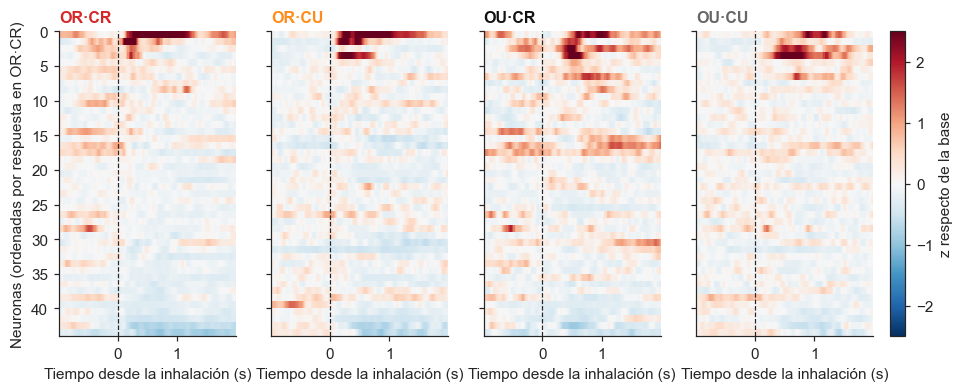

In [9]:
tc = TC["inhalacion"]
m_resp = (tc >= 0) & (tc <= 1)
orden = np.argsort(-POB["inhalacion"][1][:, m_resp].mean(1))
ver = (tc >= -1) & (tc <= 2)
fig, axs = plt.subplots(1, 4, figsize=(10, 3.6), sharey=True)
for ax, k in zip(axs, TIPOS_OLOR):
    im = ax.imshow(POB["inhalacion"][k][orden][:, ver], aspect="auto", cmap="RdBu_r", vmin=-2.5, vmax=2.5,
                   extent=[tc[ver][0], tc[ver][-1], len(ESTABLES), 0], interpolation="nearest")
    ax.axvline(0, color=TINTA, lw=0.8, ls="--")
    ax.set_title(ETIQ[k], color=COLORES[k] if k != 4 else GRIS)
    ax.set_xlabel("Tiempo desde la inhalación (s)")
axs[0].set_ylabel("Neuronas (ordenadas por respuesta en OR·CR)")
cb = fig.colorbar(im, ax=axs, fraction=0.025, pad=0.02)
cb.set_label("z respecto de la base")
guardar(fig, "parte1/mapa_poblacion_inhalacion.png")
plt.show()

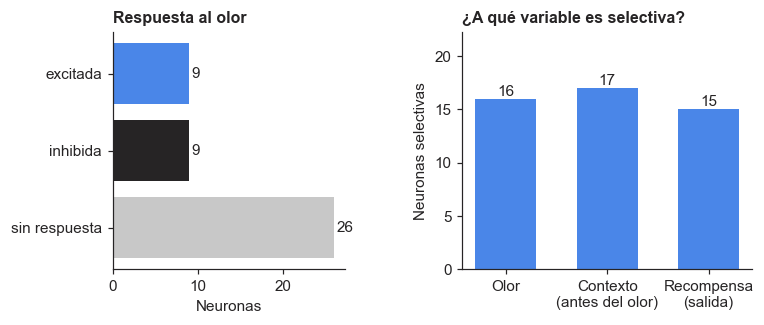

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(7.5, 2.8), gridspec_kw=dict(width_ratios=[1, 1.25], wspace=0.45))
ax = axs[0]
cats = ["excitada", "inhibida", "sin respuesta"]
vals = [int((clas.resp_olor == c).sum()) for c in cats]
ax.barh(cats[::-1], vals[::-1], color=[GRIS, TINTA, ACENTO][::-1] if False else ["#C8C8C8", TINTA, ACENTO])
for i, v in enumerate(vals[::-1]):
    ax.text(v + 0.3, i, str(v), va="center")
ax.set_xlabel("Neuronas"); ax.set_title("Respuesta al olor")
ax = axs[1]
etq = ["Olor", "Contexto\n(antes del olor)", "Recompensa\n(salida)"]
vals = clas[["sel_olor", "sel_contexto", "sel_recompensa"]].sum().values
ax.bar(etq, vals, color=ACENTO, width=0.6)
for i, v in enumerate(vals):
    ax.text(i, v + 0.3, f"{v}", ha="center")
ax.set_ylabel("Neuronas selectivas"); ax.set_title("¿A qué variable es selectiva?")
ax.set_ylim(0, max(vals) * 1.25 + 1)
guardar(fig, "parte1/clasificacion.png")
plt.show()

### Neuronas de ejemplo para la presentación
Elegimos automáticamente: la más excitada por el olor con selectividad, la más inhibida, y una selectiva a la recompensa.

Ejemplos -> excitada: 52 inhibida: 29 recompensa: 2


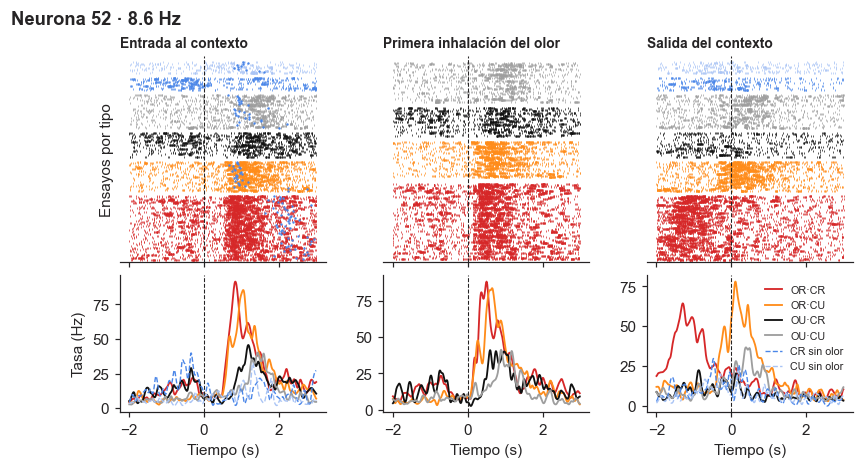

In [11]:
cand = clas[clas.resp_olor == "excitada"].copy()
cand["score"] = cand.d_olor_hz.astype(float) * (1 + cand.n_variables)
EJ_EXC = int(cand.score.idxmax())
EJ_INH = int(clas[clas.resp_olor == "inhibida"].d_olor_hz.astype(float).idxmin()) if (clas.resp_olor == "inhibida").any() else ESTABLES[0]
rec = clas[(clas.sel_recompensa) & (~clas.index.isin([EJ_EXC, EJ_INH]))]
EJ_REC = int(rec.d_olor_hz.astype(float).abs().idxmin()) if len(rec) else ESTABLES[1]
print("Ejemplos -> excitada:", EJ_EXC, "inhibida:", EJ_INH, "recompensa:", EJ_REC)
for nombre, nid in [("excitada", EJ_EXC), ("inhibida", EJ_INH), ("recompensa", EJ_REC)]:
    f = fig_neurona(nid, alineaciones=("entrada", "inhalacion", "salida"), figsize=(8.6, 4.2))
    guardar(f, f"parte1/ejemplo_{nombre}.png")
    plt.show() if nombre == "excitada" else plt.close(f)

## Parte II · Actividad poblacional

Promedio de las neuronas estables (z-score) por tipo de ensayo, ± error estándar entre neuronas. Promediar todas juntas
cancela excitaciones con inhibiciones, por eso mostramos también las excitadas y las inhibidas por el olor por separado.

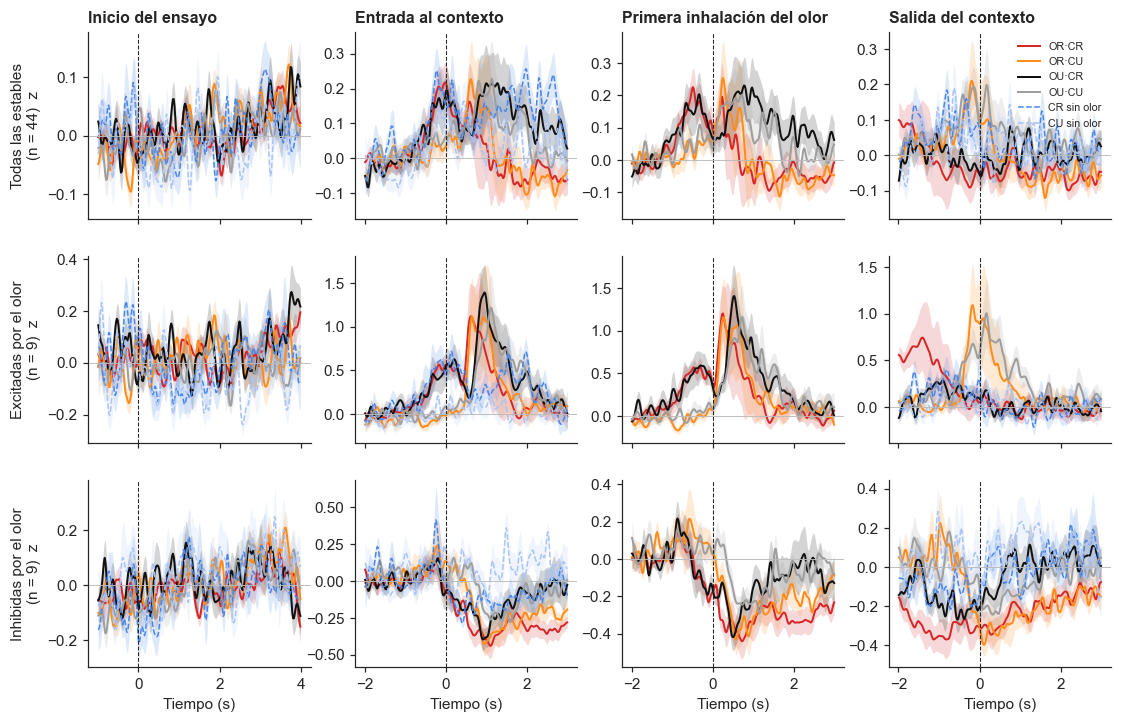

In [12]:
GRUPOS = {"Todas las estables": np.ones(len(ESTABLES), bool),
          "Excitadas por el olor": (clas.resp_olor == "excitada").values,
          "Inhibidas por el olor": (clas.resp_olor == "inhibida").values}


def panel_pob(ax, alin, mascara, tipos=None, leyenda=False):
    tc = TC[alin]
    for k in (tipos or sorted(POB[alin])):
        Z = POB[alin][k][mascara]
        if len(Z) == 0:
            continue
        m, e = Z.mean(0), Z.std(0, ddof=1) / np.sqrt(len(Z)) if len(Z) > 1 else np.zeros(Z.shape[1])
        ax.fill_between(tc, m - e, m + e, color=COLORES[k], alpha=0.18, lw=0)
        ax.plot(tc, m, color=COLORES[k], lw=1.3 if k <= 4 else 1.0, ls="-" if k <= 4 else "--", label=ETIQ[k])
    ax.axvline(0, color=TINTA, lw=0.7, ls="--"); ax.axhline(0, color="#BBBBBB", lw=0.6)
    if leyenda:
        ax.legend(fontsize=7, loc="upper right")


fig, axs = plt.subplots(3, 4, figsize=(12, 7.5), sharex="col")
for i, (g, mk) in enumerate(GRUPOS.items()):
    for j, alin in enumerate(ALIN):
        panel_pob(axs[i, j], alin, mk, leyenda=(i == 0 and j == 3))
        if i == 0:
            axs[i, j].set_title(ALIN[alin][2])
        if j == 0:
            axs[i, j].set_ylabel(f"{g}\n(n = {mk.sum()})  z")
        if i == 2:
            axs[i, j].set_xlabel("Tiempo (s)")
guardar(fig, "parte2/poblacion_completa.png")
plt.show()

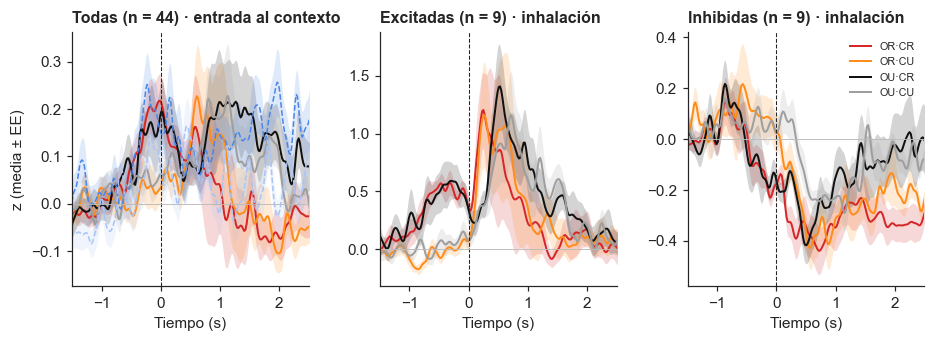

In [13]:
# Versión para la diapositiva: inhalación (excitadas / inhibidas) + entrada (todas, con ensayos sin olor)
fig, axs = plt.subplots(1, 3, figsize=(10, 3.0), gridspec_kw=dict(wspace=0.3))
panel_pob(axs[0], "entrada", GRUPOS["Todas las estables"], leyenda=False)
axs[0].set_title(f"Todas (n = {len(ESTABLES)}) · entrada al contexto"); axs[0].set_ylabel("z (media ± EE)")
panel_pob(axs[1], "inhalacion", GRUPOS["Excitadas por el olor"])
axs[1].set_title(f"Excitadas (n = {GRUPOS['Excitadas por el olor'].sum()}) · inhalación")
panel_pob(axs[2], "inhalacion", GRUPOS["Inhibidas por el olor"], leyenda=True)
axs[2].set_title(f"Inhibidas (n = {GRUPOS['Inhibidas por el olor'].sum()}) · inhalación")
for ax in axs:
    ax.set_xlabel("Tiempo (s)"); ax.set_xlim(-1.5, 2.5)
guardar(fig, "parte2/poblacion_slide.png")
plt.show()

**Cuantificación.** Respuesta media (z en 0–1 s post inhalación) de las neuronas excitadas, por tipo de ensayo.
La comparación clave es **mismo olor, distinto contexto** (OR·CR vs OR·CU y OU·CR vs OU·CU): si difieren, el contexto
modula la respuesta al olor. Test de Wilcoxon pareado entre neuronas.

OR·CR vs OR·CU p = 0.652 | OU·CR vs OU·CU p = 0.129 | OR vs OU p = 0.496


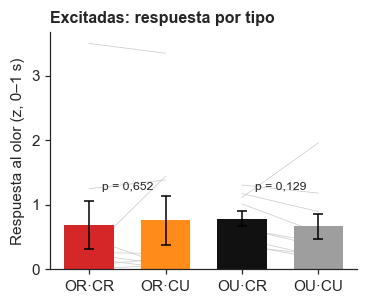

In [14]:
def resp_media(alin, k, mascara, a=0.0, b=1.0):
    tc = TC[alin]
    return POB[alin][k][mascara][:, (tc >= a) & (tc <= b)].mean(1)


mk = GRUPOS["Excitadas por el olor"]
R = {k: resp_media("inhalacion", k, mk) for k in TIPOS_OLOR}
p_or = stats.wilcoxon(R[1], R[2]).pvalue
p_ou = stats.wilcoxon(R[3], R[4]).pvalue
p_od = stats.wilcoxon((R[1] + R[2]) / 2, (R[3] + R[4]) / 2).pvalue
print(f"OR·CR vs OR·CU p = {p_or:.3g} | OU·CR vs OU·CU p = {p_ou:.3g} | OR vs OU p = {p_od:.3g}")

fig, ax = plt.subplots(figsize=(3.6, 2.8))
for i, k in enumerate(TIPOS_OLOR):
    ax.bar(i, R[k].mean(), yerr=R[k].std(ddof=1) / np.sqrt(len(R[k])), color=COLORES[k], width=0.65,
           error_kw=dict(lw=1, capsize=3))
for a_, b_ in [(R[1], R[2])]:
    for va, vb in zip(a_, b_):
        ax.plot([0, 1], [va, vb], color="#CCCCCC", lw=0.5, zorder=0)
for va, vb in zip(R[3], R[4]):
    ax.plot([2, 3], [va, vb], color="#CCCCCC", lw=0.5, zorder=0)
ax.set_xticks(range(4)); ax.set_xticklabels([ETIQ[k] for k in TIPOS_OLOR])
ax.set_ylabel("Respuesta al olor (z, 0–1 s)")


def p_txt(p):
    return "p < 0,001" if p < 0.001 else f"p = {p:.3f}".replace(".", ",")


def coma_py(x, d=1):
    return f"{x:.{d}f}".replace(".", ",")


top = max(R[k].mean() + R[k].std(ddof=1) / np.sqrt(len(R[k])) for k in TIPOS_OLOR)
ax.text(0.5, top * 1.08, p_txt(p_or), ha="center", fontsize=8)
ax.text(2.5, top * 1.08, p_txt(p_ou), ha="center", fontsize=8)
ax.set_title("Excitadas: respuesta por tipo")
guardar(fig, "parte2/respuesta_por_tipo.png")
plt.show()

## Parte III · Correlación neuronal

**Correlograma**: histograma de las diferencias de tiempo entre los spikes de una neurona A y los de una neurona B
(cross-correlograma, CCG) o de una neurona consigo misma (autocorrelograma, ACG). Se calcula sobre toda la sesión
(spikes en tiempo absoluto). Lo expresamos como **tasa condicional**: la tasa de B (Hz) en función del tiempo desde
un spike de A.

In [15]:
def correlograma(a, b, ventana, ancho, auto=False):
    """Conteos de (b - a) en bins centrados en 0, entre -ventana y +ventana."""
    nb = int(round(ventana / ancho))
    edges = (np.arange(-nb, nb + 2) - 0.5) * ancho
    lo = np.searchsorted(b, a + edges[0])
    hi = np.searchsorted(b, a + edges[-1])
    n = hi - lo
    if n.sum() == 0:
        return np.zeros(len(edges) - 1), edges[:-1] + ancho / 2
    idx = np.repeat(np.arange(len(a)), n)
    offs = np.arange(n.sum()) - np.repeat(np.cumsum(n) - n, n)
    d = b[np.repeat(lo, n) + offs] - a[idx]
    if auto:
        d = d[d != 0]
    k = np.floor((d - edges[0]) / ancho).astype(np.int64)        # bins uniformes: bincount es mucho más rápido
    k = k[(k >= 0) & (k < len(edges) - 1)]
    return np.bincount(k, minlength=len(edges) - 1).astype(float), edges[:-1] + ancho / 2

### III.a · Autocorrelogramas

Dos escalas:
- **Corta (±50 ms, bins de 1 ms)**: período refractario (hueco en 0) y disparo en ráfagas (*bursts*: pico a 2–10 ms).
  Índice de burst = tasa a 2–10 ms / tasa a 40–50 ms.
- **Larga (±1 s, bins de 10 ms)**: ritmicidad. Por el teorema de Wiener–Khinchin, el espectro del ACG es el espectro de
  potencia del tren de spikes. Le sacamos la tendencia lenta (filtro pasa-altos: ACG − ACG suavizado con σ = 100 ms) y
  medimos qué fracción de la potencia entre 1 y 30 Hz cae en **2–8 Hz** (rango de la respiración/olfateo del ratón).

**Control (surrogate)**: para saber si esa fracción es mayor que lo esperable por azar, recalculamos el índice sobre
trenes con *jitter por intervalos* de 500 ms (cada spike se mueve al azar dentro de su ventana de 500 ms). Eso conserva la
modulación lenta por la tarea (> 0,5 s) y destruye cualquier ritmo de 2–8 Hz. Una neurona es **rítmica** si su índice
supera al de los 25 surrogates por z > 3. (La ACG larga se calcula con la FFT del tren binneado: es la misma cuenta,
mucho más rápida.)

In [16]:
def jitter_intervalo(spk, delta, rng):
    return np.sort(np.floor(spk / delta) * delta + rng.uniform(0, delta, len(spk)))


def indice_ritmo(acg_larga, lags, ancho=0.01):
    pos = lags > 0.01
    x = acg_larga[pos]
    x = x - gaussian_filter1d(x, 0.1 / ancho, mode="nearest")
    x = x * np.hanning(len(x))
    nfft = 4096
    P = np.abs(np.fft.rfft(x, nfft)) ** 2
    f = np.fft.rfftfreq(nfft, ancho)
    tot = P[(f >= 1) & (f <= 30)].sum()
    banda = (f >= 2) & (f <= 8)
    return P[banda].sum() / tot, f[banda][np.argmax(P[banda])], f, P


def acg_larga(spk, ancho=0.01, maxlag=1.0):
    """ACG de escala larga vía FFT del tren binneado (mismo resultado que contar diferencias, mucho más rápido)."""
    nb = int(np.ceil(T_SESION / ancho)) + 1
    x = np.bincount((spk / ancho).astype(np.int64), minlength=nb).astype(np.float32)
    K = int(round(maxlag / ancho))
    nfft = sfft.next_fast_len(len(x) + K + 1, real=True)
    F = sfft.rfft(x, nfft, workers=-1)
    ac = sfft.irfft(F * np.conj(F), nfft, workers=-1)[:K + 1].astype(float)
    ac[0] -= x.sum()                      # quita cada spike consigo mismo
    lags = np.arange(K + 1) * ancho
    return np.r_[ac[:0:-1], ac], np.r_[-lags[:0:-1], lags]


N_SURR = 25
acg = {}
for n in ESTABLES:
    s = spikes[n]
    c_corta, lag_c = correlograma(s, s, 0.05, 0.001, auto=True)
    c_larga, lag_l = acg_larga(s)
    corta = c_corta / (len(s) * 0.001)
    larga = c_larga / (len(s) * 0.01)
    ri, fpico, _, _ = indice_ritmo(larga, lag_l)
    surr = []
    for _ in range(N_SURR):
        cj, _ = acg_larga(jitter_intervalo(s, 0.5, RNG))
        surr.append(indice_ritmo(cj / (len(s) * 0.01), lag_l)[0])
    surr = np.array(surr)
    base_c = corta[(np.abs(lag_c) >= 0.04)].mean()
    acg[n] = dict(corta=corta, larga=larga, ritmo=ri, f_pico=fpico,
                  z_ritmo=(ri - surr.mean()) / max(surr.std(ddof=1), 1e-9),
                  burst=corta[(np.abs(lag_c) >= 0.002) & (np.abs(lag_c) <= 0.01)].mean() / max(base_c, 1e-9),
                  refrac=corta[np.abs(lag_c) <= 0.0015].mean() / max(base_c, 1e-9))
LAG_C, LAG_L = lag_c, lag_l
A = pd.DataFrame({n: {k: v for k, v in d.items() if k not in ("corta", "larga")} for n, d in acg.items()}).T.astype(float)
A["ritmica"] = A.z_ritmo > 3
A["bursty"] = A.burst > 1.5
neur = neur.join(A)
print(f"Rítmicas (2–8 Hz, z>3): {A.ritmica.sum()} de {len(A)} | frecuencia pico mediana {A.loc[A.ritmica,'f_pico'].median():.1f} Hz")
print(f"Con ráfagas (índice > 1,5): {A.bursty.sum()} de {len(A)}")

Rítmicas (2–8 Hz, z>3): 16 de 44 | frecuencia pico mediana 2.8 Hz
Con ráfagas (índice > 1,5): 4 de 44


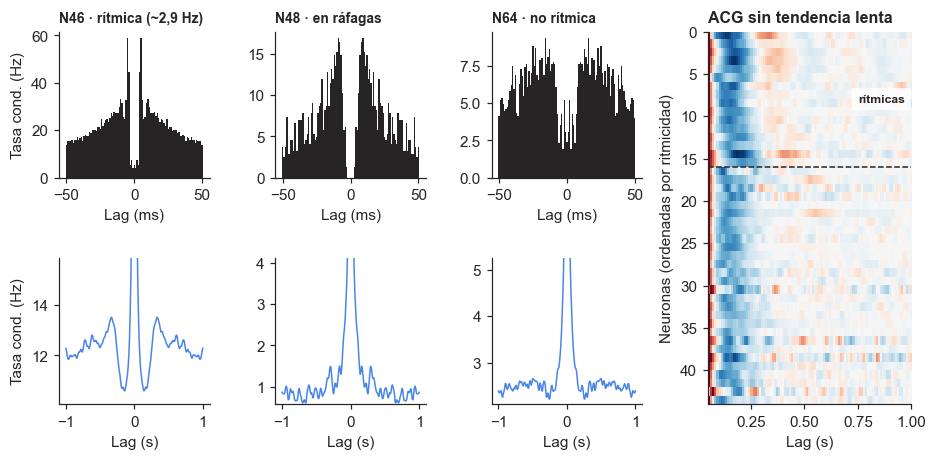

In [17]:
# Ejemplos: la más rítmica, la más bursty (no rítmica) y una "plana"
ej_r = A.z_ritmo.idxmax()
ej_b = A[~A.index.isin([ej_r])].burst.idxmax()
plano = A[(~A.ritmica) & (~A.bursty)]
ej_p = (plano.z_ritmo.abs() + (plano.burst - 1).abs()).idxmin() if len(plano) else A.z_ritmo.idxmin()
EJ_ACG = [int(ej_r), int(ej_b), int(ej_p)]
desc = {int(ej_r): f"rítmica (~{coma_py(A.loc[ej_r, 'f_pico'])} Hz)", int(ej_b): "en ráfagas", int(ej_p): "no rítmica"}

fig = plt.figure(figsize=(10, 4.4))
gs = fig.add_gridspec(2, 4, width_ratios=[1, 1, 1, 1.35], hspace=0.55, wspace=0.4)
for j, n in enumerate(EJ_ACG):
    ax = fig.add_subplot(gs[0, j])
    ax.bar(LAG_C * 1e3, acg[n]["corta"], width=1.0, color=TINTA, lw=0)
    ax.set_title(f"N{n} · {desc[n]}", fontsize=9)
    ax.set_xlabel("Lag (ms)")
    if j == 0:
        ax.set_ylabel("Tasa cond. (Hz)")
    ax = fig.add_subplot(gs[1, j])
    yl = gaussian_filter1d(acg[n]["larga"], 1)
    lejos = np.abs(LAG_L) >= 0.05
    ax.plot(LAG_L, yl, color=ACENTO, lw=1)
    ax.set_ylim(yl[lejos].min() * 0.95, yl[lejos].max() * 1.05)   # el pico central no deja ver el ritmo
    ax.set_xlabel("Lag (s)")
    if j == 0:
        ax.set_ylabel("Tasa cond. (Hz)")
ax = fig.add_subplot(gs[:, 3])
orden = A.sort_values("z_ritmo", ascending=False).index
M = []
sel = LAG_L >= 0.05
for n in orden:
    x = gaussian_filter1d(acg[n]["larga"], 1)[sel]
    x = x - gaussian_filter1d(x, 10, mode="nearest")
    M.append(x / max(np.abs(x).max(), 1e-9))
im = ax.imshow(np.array(M), aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1,
               extent=[0.05, 1, len(orden), 0], interpolation="nearest")
nr = int(A.ritmica.sum())
ax.axhline(nr, color=TINTA, lw=1, ls="--")
ax.text(0.97, nr / 2, "rítmicas", ha="right", va="center", fontsize=8, fontweight="bold",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.8))
ax.set_xlabel("Lag (s)"); ax.set_ylabel("Neuronas (ordenadas por ritmicidad)")
ax.set_title("ACG sin tendencia lenta")
guardar(fig, "parte3/autocorrelogramas.png")
plt.show()

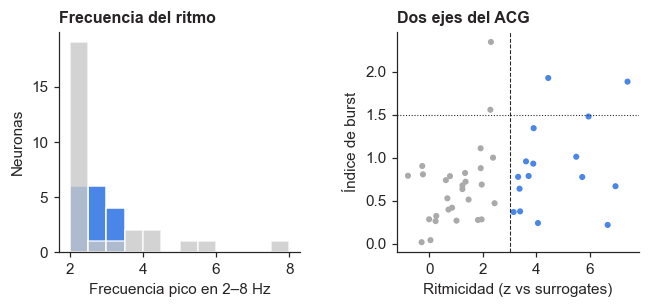

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(6.8, 2.6), gridspec_kw=dict(wspace=0.4))
ax = axs[0]
ax.hist(A.loc[A.ritmica, "f_pico"], bins=np.arange(2, 8.5, 0.5), color=ACENTO, edgecolor="white")
ax.hist(A.loc[~A.ritmica, "f_pico"], bins=np.arange(2, 8.5, 0.5), color="#C8C8C8", edgecolor="white", alpha=0.8)
ax.set_xlabel("Frecuencia pico en 2–8 Hz"); ax.set_ylabel("Neuronas")
ax.set_title("Frecuencia del ritmo")
ax = axs[1]
ax.scatter(A.z_ritmo, A.burst, c=[ACENTO if r else "#AAAAAA" for r in A.ritmica], s=16, lw=0)
ax.axvline(3, color=TINTA, ls="--", lw=0.7); ax.axhline(1.5, color=TINTA, ls=":", lw=0.7)
ax.set_xlabel("Ritmicidad (z vs surrogates)"); ax.set_ylabel("Índice de burst")
ax.set_title("Dos ejes del ACG")
guardar(fig, "parte3/ritmicidad_resumen.png")
plt.show()

### III.b · Cross-correlogramas a escala de milisegundos: posibles conexiones funcionales

Un pico angosto y **asimétrico** en el CCG a +1–4 ms (B dispara justo después de A) es la firma de una posible
conexión excitatoria A→B; un pico centrado en 0 ms indica **sincronía**, típicamente por una entrada común; un valle a
+1–5 ms, una posible inhibición.

El problema: dos neuronas que responden a los mismos eventos de la tarea tienen CCG con un "lomo" ancho aunque no estén
conectadas. Para separar eso usamos como línea de base el propio CCG suavizado con una **gaussiana hueca**
(σ = 10 ms, 60 % de hueco en el centro; Stark & Abeles 2009). Esa base conserva todas las co-variaciones lentas (> ~10 ms),
y es el equivalente analítico de hacer *jitter* de los spikes. Cada bin se compara con su base con un test de Poisson.

Criterios (α por bin = 10⁻⁴; con ~900 pares × ~16 bins esperamos ~1–2 falsos positivos en total):
- **Artefacto de sorting** (se excluye): un único bin gigante (> 3× la base) en |lag| ≤ 1 ms, más de 2,5 veces
  mayor que sus "hombros" a 2–4 ms.
  Es lo que produce un mismo spike asignado a dos unidades, o una neurona partida en dos clusters.
- **Dirigida A→B**: algún bin en +1…+4 ms supera la base y del lado anticausal (−4…−1 ms) no hay nada (p > 0,01).
- **Sincronía fina**: exceso a ambos lados, o centrado en |lag| ≤ 1 ms. Típico de entrada común u oscilaciones rápidas.
- **Inhibitoria A→B**: algún bin en +1…+5 ms queda por debajo de la base.
- Sólo se testean pares con ≥ 5 coincidencias esperadas por bin.
- Una "posible conexión" en el CCG es una hipótesis: sin la posición de los electrodos ni manipulaciones no se puede
  distinguir una sinapsis de una entrada común con retardos distintos.

In [19]:
def base_gauss_hueca(ccg, sigma=10, hueco=0.6):
    half = int(3 * sigma)
    x = np.arange(-half, half + 1)
    w = np.exp(-x ** 2 / (2 * sigma ** 2))
    w /= w.sum()
    w[half] *= (1 - hueco)
    w /= w.sum()
    pad = np.r_[ccg[half:0:-1], ccg, ccg[-2:-half - 2:-1]]
    return np.convolve(pad, w, mode="valid")


def p_exceso(c, lam):
    return np.clip(1 - stats.poisson.cdf(c - 1, lam) - 0.5 * stats.poisson.pmf(c, lam), 0, 1)


def p_defecto(c, lam):
    return np.clip(stats.poisson.cdf(c - 1, lam) + 0.5 * stats.poisson.pmf(c, lam), 0, 1)


ALFA_CCG = 1e-4
pares = []
CCG = {}
for i, a in enumerate(ESTABLES):
    for b in ESTABLES[i + 1:]:
        c, lag = correlograma(spikes[a], spikes[b], 0.05, 0.001)
        base = base_gauss_hueca(c)
        CCG[(a, b)] = (c, base)
        L = np.round(lag * 1e3).astype(int)
        pos, neg, cero = (L >= 1) & (L <= 4), (L <= -1) & (L >= -4), np.abs(L) <= 1
        testeable = base[np.abs(L) <= 5].mean() >= 5
        pe, pdf = p_exceso(c, base), p_defecto(c, base)
        ratio = c / np.maximum(base, 1e-9)
        # Artefacto de sorting: un pico gigante (> 3x la base) en |lag| <= 1 ms sin "hombros" a 2-4 ms.
        # Un mismo spike asignado a dos unidades (o una unidad partida) produce exactamente eso.
        pico1 = ratio[np.abs(L) <= 1].max()
        artefacto = testeable and pico1 > 3 and pico1 > 2.5 * ratio[(np.abs(L) >= 2) & (np.abs(L) <= 4)].mean()
        causal, anticausal = pe[pos].min() < ALFA_CCG, pe[neg].min() < ALFA_CCG
        ok = testeable and not artefacto
        r = dict(a=a, b=b, testeable=testeable, artefacto=artefacto, n_coinc=c.sum(),
                 exc_ab=ok and causal and pe[neg].min() > 0.01,          # pico sólo del lado causal
                 exc_ba=ok and anticausal and pe[pos].min() > 0.01,
                 sincronia=ok and ((pe[cero].min() < ALFA_CCG and not (causal ^ anticausal)) or (causal and anticausal)),
                 inh_ab=ok and pdf[(L >= 1) & (L <= 5)].min() < ALFA_CCG,
                 inh_ba=ok and pdf[(L <= -1) & (L >= -5)].min() < ALFA_CCG)
        exc = ratio - 1
        win = np.abs(L) <= 5
        r["lag_pico_ms"] = L[win][np.argmax(exc[win])]
        r["exceso_pico"] = exc[win].max()
        pares.append(r)
LAG_CCG = lag
pares = pd.DataFrame(pares)
pares["significativo"] = pares[["exc_ab", "exc_ba", "sincronia", "inh_ab", "inh_ba"]].any(axis=1)
nt = int(pares.testeable.sum())
print(f"Pares testeables: {nt} de {len(pares)}")
print(f"  Probables artefactos de sorting: {int(pares.artefacto.sum())}")
print(f"  Excitatorios dirigidos: {int(pares.exc_ab.sum() + pares.exc_ba.sum())}")
print(f"  Sincronía fina (bilateral o 0 ms): {int(pares.sincronia.sum())}")
print(f"  Inhibitorios:           {int(pares.inh_ab.sum() + pares.inh_ba.sum())}")
print(f"  Algún tipo:             {int(pares.significativo.sum())} ({100*pares.significativo.sum()/max(nt,1):.1f} % de los testeables)")
print(f"  Exceso mediano en los significativos: {100*pares.loc[pares.significativo,'exceso_pico'].median():.0f} %")
print(f"  Falsos positivos esperados ~ {nt * 16 * ALFA_CCG:.1f}")
grado = pd.concat([pares.loc[pares.significativo, "a"], pares.loc[pares.significativo, "b"]]).value_counts()
rho_tasa = stats.spearmanr(neur.loc[ESTABLES, "tasa_hz"], grado.reindex(ESTABLES).fillna(0))
print(f"  Interacciones por neurona vs tasa: Spearman rho = {rho_tasa.statistic:.2f} (p = {rho_tasa.pvalue:.2g})")

Pares testeables: 909 de 946
  Probables artefactos de sorting: 10
  Excitatorios dirigidos: 85
  Sincronía fina (bilateral o 0 ms): 43
  Inhibitorios:           40
  Algún tipo:             140 (15.4 % de los testeables)
  Exceso mediano en los significativos: 40 %
  Falsos positivos esperados ~ 1.5
  Interacciones por neurona vs tasa: Spearman rho = 0.65 (p = 1.8e-06)


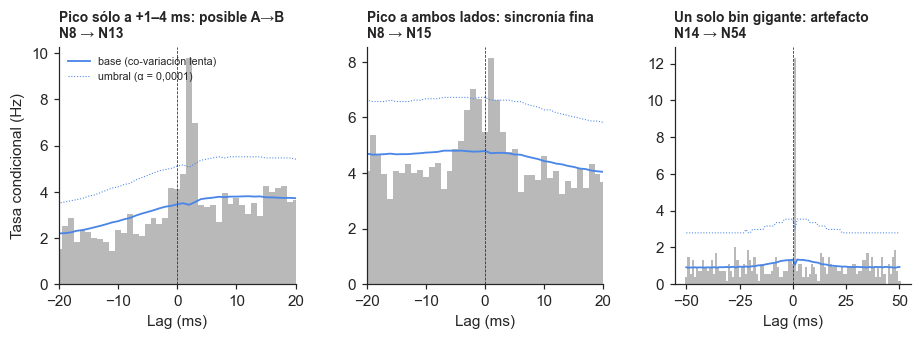

In [20]:
def panel_ccg(ax, a, b, titulo):
    c, base = CCG[(a, b)] if (a, b) in CCG else (CCG[(b, a)][0][::-1], CCG[(b, a)][1][::-1])
    t = LAG_CCG * 1e3
    hz = 1 / (len(spikes[a]) * 0.001)
    ax.bar(t, c * hz, width=1.0, color="#B9B9B9", lw=0)
    ax.plot(t, base * hz, color=ACENTO, lw=1.2, label="base (co-variación lenta)")
    lim = stats.poisson.ppf(1 - ALFA_CCG, base) * hz
    ax.plot(t, lim, color=ACENTO, lw=0.7, ls=":", label="umbral (α = 0,0001)")
    ax.axvline(0, color=TINTA, lw=0.5, ls="--")
    ax.set_title(titulo + f"\nN{a} → N{b}", fontsize=9)
    ax.set_xlabel("Lag (ms)")


def elegir(df, col):
    d = df[df[col]].sort_values("exceso_pico", ascending=False)
    return (int(d.iloc[0].a), int(d.iloc[0].b)) if len(d) else None


ej_exc = elegir(pares, "exc_ab")
if ej_exc is None:
    tmp = elegir(pares, "exc_ba")
    ej_exc = (tmp[1], tmp[0]) if tmp else None
bil = pares[pares.sincronia].copy()
bil["bilat"] = [min((CCG[(r.a, r.b)][0] / CCG[(r.a, r.b)][1])[np.r_[48:50]].mean(),
                    (CCG[(r.a, r.b)][0] / CCG[(r.a, r.b)][1])[np.r_[51:53]].mean()) for r in bil.itertuples()]
ej_sin = (int(bil.sort_values("bilat").iloc[-1].a), int(bil.sort_values("bilat").iloc[-1].b)) if len(bil) else None
ej_art = elegir(pares, "artefacto")
EJ_CCG = [(ej_exc, "Pico sólo a +1–4 ms: posible A→B"), (ej_sin, "Pico a ambos lados: sincronía fina"),
          (ej_art, "Un solo bin gigante: artefacto")]

fig, axs = plt.subplots(1, 3, figsize=(10, 2.8), gridspec_kw=dict(wspace=0.3))
for ax, (par, tit) in zip(axs, EJ_CCG):
    if par:
        panel_ccg(ax, par[0], par[1], tit)
        if "artefacto" in tit:
            ax.title.set_color("#D62728")
axs[0].set_ylabel("Tasa condicional (Hz)")
axs[0].legend(fontsize=7, loc="upper left")
for ax in axs[:2]:                       # zoom a ±20 ms para ver la forma del pico
    ax.set_xlim(-20, 20)
guardar(fig, "parte3/ccg_ejemplos.png")
plt.show()

**Mapa de conexiones funcionales.** Neuronas en círculo, coloreadas por su respuesta al olor (Parte I). Flechas:
posibles conexiones excitatorias dirigidas; líneas: sincronía; flechas rojas punteadas: posibles inhibiciones.

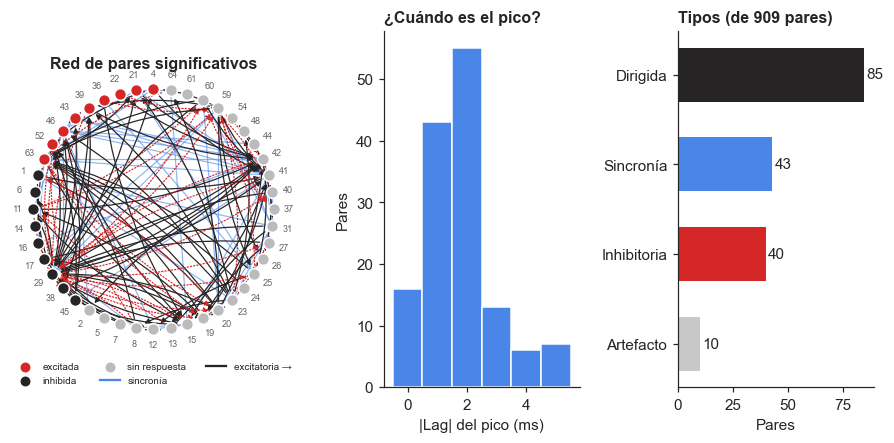

In [21]:
COL_RESP = {"excitada": "#D62728", "inhibida": TINTA, "sin respuesta": "#BBBBBB"}
orden_nodos = sorted(ESTABLES, key=lambda n: (["excitada", "inhibida", "sin respuesta"].index(clas.loc[n, "resp_olor"]), n))
ang = np.linspace(0, 2 * np.pi, len(orden_nodos), endpoint=False) + np.pi / 2
pos = {n: (np.cos(t), np.sin(t)) for n, t in zip(orden_nodos, ang)}

fig = plt.figure(figsize=(10, 4.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1.35, 1, 1], wspace=0.45)
ax = fig.add_subplot(gs[0])
for r in pares.itertuples():
    pa, pb = pos[r.a], pos[r.b]
    if r.sincronia:
        ax.plot([pa[0], pb[0]], [pa[1], pb[1]], color=ACENTO, lw=0.8, alpha=0.6, zorder=1)
    for flag, (o, d), col, ls in [(r.exc_ab, (pa, pb), TINTA, "-"), (r.exc_ba, (pb, pa), TINTA, "-"),
                                  (r.inh_ab, (pa, pb), "#D62728", ":"), (r.inh_ba, (pb, pa), "#D62728", ":")]:
        if flag:
            ax.add_patch(FancyArrowPatch(o, d, arrowstyle="-|>", mutation_scale=7, color=col, lw=0.8, ls=ls,
                                         shrinkA=6, shrinkB=6, connectionstyle="arc3,rad=0.12", zorder=2))
for n in orden_nodos:
    ax.scatter(*pos[n], s=60, color=COL_RESP[clas.loc[n, "resp_olor"]], edgecolor="white", zorder=3)
    ax.text(pos[n][0] * 1.13, pos[n][1] * 1.13, str(n), ha="center", va="center", fontsize=6, color=GRIS)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Red de pares significativos", loc="center")
for lab, col in COL_RESP.items():
    ax.scatter([], [], color=col, s=30, label=lab)
ax.plot([], [], color=ACENTO, label="sincronía"); ax.plot([], [], color=TINTA, label="excitatoria →")
ax.legend(fontsize=6.5, loc="lower center", bbox_to_anchor=(0.5, -0.2), ncol=3)

ax = fig.add_subplot(gs[1])
sig = pares[pares.significativo & (pares.exceso_pico > 0)]
ax.hist(sig.lag_pico_ms.abs(), bins=np.arange(-0.5, 6.5, 1), color=ACENTO, edgecolor="white")
ax.set_xlabel("|Lag| del pico (ms)"); ax.set_ylabel("Pares"); ax.set_title("¿Cuándo es el pico?")

ax = fig.add_subplot(gs[2])
cat = {"Dirigida": int(pares.exc_ab.sum() + pares.exc_ba.sum()),
       "Sincronía": int(pares.sincronia.sum()),
       "Inhibitoria": int(pares.inh_ab.sum() + pares.inh_ba.sum()),
       "Artefacto": int(pares.artefacto.sum())}
etq_cat = [k.replace(chr(10), " ") for k in cat][::-1]
ax.barh(etq_cat, list(cat.values())[::-1], color=[TINTA, ACENTO, "#D62728", "#C8C8C8"][::-1], height=0.6)
for i, v in enumerate(list(cat.values())[::-1]):
    ax.text(v + 1, i, str(v), va="center")
ax.set_xlabel("Pares"); ax.set_title(f"Tipos (de {nt} pares)")
guardar(fig, "parte3/red_conexiones.png")
plt.show()

### III.c · Cross-correlación a escala de cientos de ms: ¿estímulo compartido o coordinación?

A escala lenta (±500 ms, bins de 10 ms) dos neuronas pueden estar correlacionadas simplemente porque **ambas responden
al olor**. El **shift predictor** (Perkel et al. 1967) estima esa parte: correlamos la neurona A del ensayo *i* con la
neurona B del ensayo siguiente **del mismo tipo**. Mantiene la relación con el estímulo y rompe todo lo que ocurre
"dentro del mismo ensayo". CCG crudo − shift predictor = coordinación que no se explica por la respuesta al estímulo.

Ventana: −1 a +2 s alrededor de la primera inhalación, ensayos 1–4. Índice por par: coincidencias en ±100 ms por
encima del shift predictor, en % de lo que predice el shift (0 % = todo se explica por el estímulo).

In [22]:
VEN_SP = (-1.0, 2.0)
tr_sp = VALIDOS[VALIDOS.tipo.isin(TIPOS_OLOR)].copy()
OFFSET = 100.0   # cada ensayo se coloca en su propio tramo de tiempo para no mezclar ensayos
tr_sp["orden"] = np.arange(len(tr_sp))
sig_tr = tr_sp.groupby("tipo").orden.transform(lambda x: np.roll(x.values, -1))   # ensayo siguiente del mismo tipo


def tren_ensayos(spk, ev, orden_destino):
    rel = alinear(spk, ev, VEN_SP)
    return np.sort(np.concatenate([r + OFFSET * o for r, o in zip(rel, orden_destino)]))


TREN = {n: tren_ensayos(spikes[n], tr_sp.t_inhal.values, tr_sp.orden.values) for n in ESTABLES}
TREN_SH = {n: tren_ensayos(spikes[n], tr_sp.t_inhal.values, sig_tr.values) for n in ESTABLES}

sp_res = []
SP = {}
for i, a in enumerate(ESTABLES):
    for b in ESTABLES[i + 1:]:
        cr, lg = correlograma(TREN[a], TREN[b], 0.5, 0.01)
        cs, _ = correlograma(TREN[a], TREN_SH[b], 0.5, 0.01)
        SP[(a, b)] = (cr, cs)
        w = np.abs(lg) <= 0.1
        # coincidencias en ±100 ms por encima de lo que predice el estímulo, en % de lo predicho
        sp_res.append(dict(a=a, b=b, crudo=cr[w].sum(), pred=cs[w].sum(),
                           exceso_intra=100 * (cr[w].sum() - cs[w].sum()) / max(cs[w].sum(), 1e-9)))
LAG_SP = lg
sp_res = pd.DataFrame(sp_res)
sp_res = sp_res[sp_res.pred > 50]          # pares con suficientes coincidencias para estimar
p_intra = stats.wilcoxon(sp_res.exceso_intra).pvalue
print(f"Coincidencias (±100 ms) por encima del shift predictor: mediana {sp_res.exceso_intra.median():.1f} % "
      f"(IQR {sp_res.exceso_intra.quantile(.25):.1f} a {sp_res.exceso_intra.quantile(.75):.1f} %), "
      f"Wilcoxon vs 0: p = {p_intra:.2g}, n = {len(sp_res)} pares")

Coincidencias (±100 ms) por encima del shift predictor: mediana 2.6 % (IQR -5.1 a 11.0 %), Wilcoxon vs 0: p = 3.4e-12, n = 936 pares


**Correlaciones de ruido (r_sc).** Pasando de milisegundos a ensayos: para cada par, correlación de Pearson entre los
conteos de spikes por ensayo en la ventana de olor (0–1 s), después de restar la media de cada tipo de ensayo. Mide
cuánto co-varían las dos neuronas de un ensayo a otro **para el mismo estímulo**. ¿Los pares con interacción
significativa en el CCG tienen más correlación de ruido?

In [23]:
cont = np.array([tasa_ventana(spikes[n], tr_sp.t_inhal.values, 0, 1.0) for n in ESTABLES])
res = cont.copy()
for k in TIPOS_OLOR:
    m = tr_sp.tipo.values == k
    res[:, m] = (cont[:, m] - cont[:, m].mean(1, keepdims=True)) / np.maximum(cont[:, m].std(1, keepdims=True), 1e-9)
RSC = np.corrcoef(res)
ix = {n: i for i, n in enumerate(ESTABLES)}
pares["r_sc"] = [RSC[ix[r.a], ix[r.b]] for r in pares.itertuples()]
pares = pares.merge(sp_res[["a", "b", "exceso_intra"]], on=["a", "b"], how="left")
g_sig = pares.loc[pares.significativo, "r_sc"]
g_ns = pares.loc[pares.testeable & ~pares.significativo & ~pares.artefacto, "r_sc"]
p_rsc = stats.mannwhitneyu(g_sig, g_ns).pvalue
p_rsc0 = stats.wilcoxon(pares.loc[~pares.artefacto, "r_sc"]).pvalue
ei_sig = pares.loc[pares.significativo, "exceso_intra"].dropna()
ei_ns = pares.loc[pares.testeable & ~pares.significativo & ~pares.artefacto, "exceso_intra"].dropna()
p_ei = stats.mannwhitneyu(ei_sig, ei_ns).pvalue
print(f"r_sc media: {pares.r_sc.mean():.3f} (vs 0: p = {p_rsc0:.2g}) | con interacción {g_sig.mean():.3f} "
      f"vs sin {g_ns.mean():.3f} (p = {p_rsc:.2g})")
print(f"Exceso intra-ensayo: con interacción {ei_sig.median():.1f} % vs sin {ei_ns.median():.1f} % (p = {p_ei:.2g})")

r_sc media: 0.027 (vs 0: p = 1.6e-10) | con interacción 0.045 vs sin 0.026 (p = 0.029)
Exceso intra-ensayo: con interacción 4.1 % vs sin 2.4 % (p = 0.019)


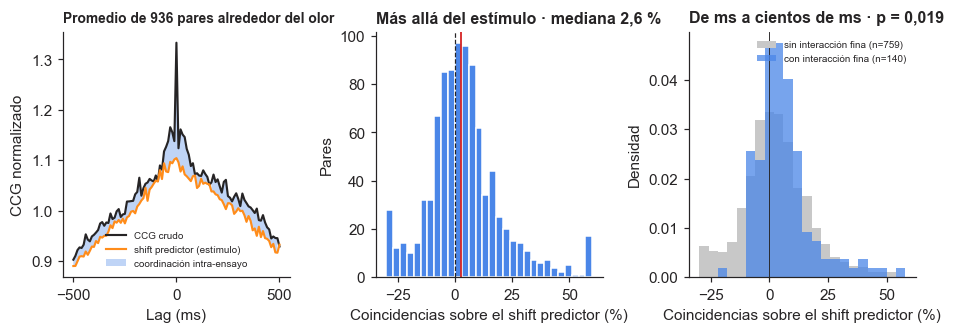

In [24]:
sin_art = [k for k in SP if not pares.loc[(pares.a == k[0]) & (pares.b == k[1]), "artefacto"].any()]
CR_ALL = np.array([SP[k][0] for k in sin_art]); CS_ALL = np.array([SP[k][1] for k in sin_art])
norm_ = CS_ALL.mean(1, keepdims=True)
crm, csm = (CR_ALL / norm_).mean(0), (CS_ALL / norm_).mean(0)
fig, axs = plt.subplots(1, 3, figsize=(10, 2.9), gridspec_kw=dict(wspace=0.38))
ax = axs[0]
ax.plot(LAG_SP * 1e3, crm, color=TINTA, lw=1.4, label="CCG crudo")
ax.plot(LAG_SP * 1e3, csm, color="#FF8C1A", lw=1.4, label="shift predictor (estímulo)")
ax.fill_between(LAG_SP * 1e3, csm, crm, where=crm > csm, color=ACENTO, alpha=0.35, lw=0, label="coordinación intra-ensayo")
ax.set_xlabel("Lag (ms)"); ax.set_ylabel("CCG normalizado")
ax.set_title(f"Promedio de {len(sin_art)} pares alrededor del olor", fontsize=9)
ax.legend(fontsize=6.5, loc="lower center")
ax = axs[1]
ax.hist(np.clip(sp_res.exceso_intra, -30, 60), bins=np.arange(-30, 61, 3), color=ACENTO, edgecolor="white")
ax.axvline(0, color=TINTA, ls="--", lw=0.8)
ax.axvline(sp_res.exceso_intra.median(), color="#D62728", lw=1.2)
ax.set_xlabel("Coincidencias sobre el shift predictor (%)"); ax.set_ylabel("Pares")
ax.set_title(f"Más allá del estímulo · mediana {coma_py(sp_res.exceso_intra.median())} %")
ax = axs[2]
bins = np.arange(-30, 61, 4)
ax.hist(np.clip(ei_ns, -30, 60), bins=bins, color="#C8C8C8", density=True, label=f"sin interacción fina (n={len(ei_ns)})")
ax.hist(np.clip(ei_sig, -30, 60), bins=bins, color=ACENTO, alpha=0.75, density=True, label=f"con interacción fina (n={len(ei_sig)})")
ax.axvline(0, color=TINTA, lw=0.6)
ax.set_xlabel("Coincidencias sobre el shift predictor (%)"); ax.set_ylabel("Densidad")
ax.set_title(f"De ms a cientos de ms · {p_txt(p_ei)}")
ax.legend(fontsize=6.5, loc="upper right")
guardar(fig, "parte3/shift_predictor_rsc.png")
plt.show()

### Resumen numérico (se usa en la presentación)

In [25]:
resumen = {
    "neuronas": len(NEURONAS), "estables": len(ESTABLES), "ensayos": len(trials),
    "pares": len(pares), "pares_testeables": nt,
    "excitadas_olor": int((clas.resp_olor == "excitada").sum()),
    "inhibidas_olor": int((clas.resp_olor == "inhibida").sum()),
    "sel_olor": int(clas.sel_olor.sum()), "sel_contexto": int(clas.sel_contexto.sum()),
    "sel_recompensa": int(clas.sel_recompensa.sum()), "mixtas_2omas": int((clas.n_variables >= 2).sum()),
    "p_OR_CRvsCU": p_or, "p_OU_CRvsCU": p_ou, "p_OR_vs_OU": p_od,
    "ritmicas": int(A.ritmica.sum()), "f_pico_mediana": float(A.loc[A.ritmica, "f_pico"].median()) if A.ritmica.any() else np.nan,
    "bursty": int(A.bursty.sum()),
    "exc_dirigidas": int(pares.exc_ab.sum() + pares.exc_ba.sum()), "sincronia": int(pares.sincronia.sum()),
    "inhibitorias": int(pares.inh_ab.sum() + pares.inh_ba.sum()), "pares_sig": int(pares.significativo.sum()),
    "fp_esperados": nt * 16 * ALFA_CCG,
    "artefactos": int(pares.artefacto.sum()), "exceso_mediano_sig": float(pares.loc[pares.significativo, "exceso_pico"].median()),
    "rho_grado_tasa": float(rho_tasa.statistic), "p_grado_tasa": float(rho_tasa.pvalue),
    "exceso_intra_mediana": float(sp_res.exceso_intra.median()), "p_intra": float(p_intra), "n_sp": int(len(sp_res)),
    "exceso_intra_sig": float(ei_sig.median()), "exceso_intra_ns": float(ei_ns.median()), "p_ei": float(p_ei),
    "rsc_media": float(pares.r_sc.mean()), "p_rsc0": float(p_rsc0), "rsc_sig": float(g_sig.mean()),
    "rsc_ns": float(g_ns.mean()), "p_rsc": p_rsc,
    "selectivas_2omas": int((clas.n_variables >= 2).sum()),
    "ej_exc": EJ_EXC, "ej_inh": EJ_INH, "ej_rec": EJ_REC, "ej_acg": EJ_ACG,
    "ej_ccg": [p for p, _ in EJ_CCG],
    "dur_ctx_mediana": trials.groupby("tipo").dur_contexto.median().round(2).to_dict(),
}
pd.Series(resumen, dtype=object).to_json(FIG / "resumen.json", force_ascii=False, indent=1, default_handler=str)
neur.to_csv(FIG / "tabla_neuronas.csv")
pares.to_csv(FIG / "tabla_pares.csv", index=False)
pd.Series(resumen, dtype=object)

neuronas                                                               64
estables                                                               44
ensayos                                                               176
pares                                                                 946
pares_testeables                                                      909
excitadas_olor                                                          9
inhibidas_olor                                                          9
sel_olor                                                               16
sel_contexto                                                           17
sel_recompensa                                                         15
mixtas_2omas                                                           17
p_OR_CRvsCU                                                      0.652344
p_OU_CRvsCU                                                      0.128906
p_OR_vs_OU                            

## Parte IV · Análisis libre

### Pregunta
**¿El contexto recompensado cambia cómo se coordinan las neuronas de la corteza piriforme, y no sólo cuánto disparan?**

Sub-análisis (ensambles): **¿las neuronas que se coordinan son las que responden parecido?** Y si el contexto cambia la
coordinación, **¿lo hace sobre todo entre esas neuronas?**

**Por qué esta pregunta.** La Parte II mostró que la población *anticipa* el contexto recompensado (la actividad sube
antes del olor) y la Parte III que las neuronas no son independientes: co-varían a escala de ms y de ensayo a ensayo.
Juntando las dos: si el contexto cambia el estado de la red (expectativa, atención, arousal), debería notarse en la
**variabilidad compartida**, no sólo en la tasa media. En corteza visual, la atención baja las correlaciones de ruido
(Cohen & Maunsell 2009); un estado de expectativa común a toda la red podría, al revés, subirlas. Por eso la dirección
queda abierta.

**Hipótesis.**
- **H1**: la correlación de ruido (r_sc) difiere entre el contexto recompensado (CR) y el no recompensado (CU) en la
  aproximación y durante el olor, pero **no** en el corredor, antes de ver el contexto (control negativo).
- **H2** (ensambles): la coordinación es mayor entre neuronas con respuestas parecidas (*like-to-like*), y el cambio por
  contexto se concentra en esos pares.

**Diseño** (r_sc: correlación de Pearson entre los conteos por ensayo de dos neuronas, restando la media y dividiendo por
el desvío de cada tipo de ensayo, para quedarnos sólo con la co-variación de ensayo a ensayo):

| Época | Ventana | Comparación |
|---|---|---|
| Corredor (control) | 0,5–2 s desde el inicio | CR (1, 3, 5) vs CU (2, 4, 6) |
| Aproximación | −1 a 0 s antes de entrar | CR (1, 3, 5) vs CU (2, 4, 6) |
| Olor | 0–0,5 s tras la inhalación | OR·CR vs OR·CU · OU·CR vs OU·CU (mismo olor, distinto contexto) |

La ventana de olor termina a los 0,5 s porque en el contexto no recompensado el ratón sale ~0,5 s después de inhalar:
así las dos condiciones se comparan dentro del contexto.

**Plan completo** (esta entrega cubre IV.1 y IV.2; el resto está en `HANDOFF_parte_IV.md`):
IV.1 r_sc por contexto y época con controles · IV.2 ensambles: semejanza de respuesta vs acoplamiento ·
IV.3 CCG de ms por contexto · IV.4 ¿la coordinación ayuda o perjudica a decodificar el olor? ·
IV.5 ensambles por clustering · IV.6 control de la velocidad y cierre.

In [26]:
VERDE_CR, GRIS_CU = "#4C9A2A", "#8C8C8C"           # contexto verde = recompensado (esquema de la tarea)
ODOR_CLASE = {1: "OR", 2: "OR", 3: "OU", 4: "OU", 5: "sin", 6: "sin"}
CTX = {1: "CR", 2: "CU", 3: "CR", 4: "CU", 5: "CR", 6: "CU"}

pares_ok = pares.loc[~pares.artefacto].reset_index(drop=True)          # sin artefactos de sorting
IA = pares_ok.a.map(ix).values
IB = pares_ok.b.map(ix).values

EPOCAS = {"Corredor": ("t_inicio", 0.5, 2.0), "Aproximación": ("t_entrada", -1.0, 0.0), "Olor": ("t_inhal", 0.0, 0.5)}
COMPARACIONES = [  # (época, etiqueta, tipos incluidos)
    ("Corredor", "CR vs CU", [1, 2, 3, 4, 5, 6]),
    ("Aproximación", "CR vs CU", [1, 2, 3, 4, 5, 6]),
    ("Olor", "OR: CR vs CU", [1, 2]),
    ("Olor", "OU: CR vs CU", [3, 4]),
]
N_PERM = 1000


def conteos_epoca(epoca, tr):
    col, a, b = EPOCAS[epoca]
    ev = tr[col].values
    return np.array([np.searchsorted(spikes[n], ev + b) - np.searchsorted(spikes[n], ev + a) for n in ESTABLES], float)


def rsc_pares(C, clase):
    """r_sc de todos los pares (sin artefactos): z-score dentro de cada clase de olor y correlación entre ensayos."""
    X = C.copy()
    for o in np.unique(clase):
        m = clase == o
        mu = X[:, m].mean(1, keepdims=True)
        sd = X[:, m].std(1, keepdims=True)
        X[:, m] = np.where(sd > 0, (X[:, m] - mu) / np.where(sd > 0, sd, 1), 0.0)
    with np.errstate(invalid="ignore", divide="ignore"):
        R = np.corrcoef(X)
    return R[IA, IB]


def efecto_contexto(C, clase, ctx):
    """Δ r_sc medio (CR − CU) y el mismo efecto ajustado por la tasa geométrica del par (regresión lineal)."""
    r_cr, r_cu = rsc_pares(C[:, ctx == "CR"], clase[ctx == "CR"]), rsc_pares(C[:, ctx == "CU"], clase[ctx == "CU"])
    ok = np.isfinite(r_cr) & np.isfinite(r_cu)
    tasa = lambda m: np.sqrt(np.maximum(C[IA][:, m].mean(1), 1e-3) * np.maximum(C[IB][:, m].mean(1), 1e-3))
    g_cr, g_cu = tasa(ctx == "CR"), tasa(ctx == "CU")
    y = np.r_[r_cr[ok], r_cu[ok]]
    Xr = np.c_[np.ones(2 * ok.sum()), np.r_[np.ones(ok.sum()), np.zeros(ok.sum())], np.log(np.r_[g_cr[ok], g_cu[ok]])]
    beta = np.linalg.lstsq(Xr, y, rcond=None)[0]
    return dict(r_cr=r_cr, r_cu=r_cu, ok=ok, delta=np.mean(r_cr[ok] - r_cu[ok]), delta_aj=beta[1], g_cr=g_cr, g_cu=g_cu)


RES4 = {}
for epoca, etq, tipos in COMPARACIONES:
    tr = VALIDOS[VALIDOS.tipo.isin(tipos)]
    if epoca == "Olor":
        tr = tr[tr.tipo.isin(TIPOS_OLOR)]
    C = conteos_epoca(epoca, tr)
    clase = tr.tipo.map(ODOR_CLASE).values
    ctx = tr.tipo.map(CTX).values
    obs = efecto_contexto(C, clase, ctx)
    nulo, nulo_aj = np.empty(N_PERM), np.empty(N_PERM)
    for i in range(N_PERM):                      # permuto la etiqueta de contexto dentro de cada clase de olor
        ctx_p = ctx.copy()
        for o in np.unique(clase):
            m = np.where(clase == o)[0]
            ctx_p[m] = RNG.permutation(ctx[m])
        e = efecto_contexto(C, clase, ctx_p)
        nulo[i], nulo_aj[i] = e["delta"], e["delta_aj"]
    obs["p"] = (np.sum(np.abs(nulo) >= abs(obs["delta"])) + 1) / (N_PERM + 1)
    obs["p_aj"] = (np.sum(np.abs(nulo_aj) >= abs(obs["delta_aj"])) + 1) / (N_PERM + 1)
    obs["nulo"], obs["nulo_aj"] = nulo, nulo_aj
    obs["mde"] = float(np.quantile(np.abs(nulo), 0.95))   # |Δ| que habríamos detectado con p < 0,05
    obs["n_cr"], obs["n_cu"] = int((ctx == "CR").sum()), int((ctx == "CU").sum())
    obs["tasa_cr"], obs["tasa_cu"] = C[:, ctx == "CR"].mean() / (EPOCAS[epoca][2] - EPOCAS[epoca][1]), \
        C[:, ctx == "CU"].mean() / (EPOCAS[epoca][2] - EPOCAS[epoca][1])
    RES4[(epoca, etq)] = obs
    print(f"{epoca:13s} {etq:13s} n={obs['n_cr']}/{obs['n_cu']}  r_sc CR={np.nanmean(obs['r_cr'][obs['ok']]):.3f} "
          f"CU={np.nanmean(obs['r_cu'][obs['ok']]):.3f}  Δ={obs['delta']:+.3f} (p={obs['p']:.3f})  "
          f"Δ ajust. tasa={obs['delta_aj']:+.3f} (p={obs['p_aj']:.3f})  tasa media CR/CU={obs['tasa_cr']:.2f}/{obs['tasa_cu']:.2f} Hz"
          f"  |Δ| detectable ≈ {obs['mde']:.3f}")

Corredor      CR vs CU      n=100/75  r_sc CR=0.017 CU=0.014  Δ=+0.003 (p=0.750)  Δ ajust. tasa=+0.003 (p=0.743)  tasa media CR/CU=5.75/5.74 Hz  |Δ| detectable ≈ 0.016


Aproximación  CR vs CU      n=100/75  r_sc CR=0.019 CU=0.021  Δ=-0.002 (p=0.776)  Δ ajust. tasa=-0.001 (p=0.874)  tasa media CR/CU=6.55/5.97 Hz  |Δ| detectable ≈ 0.015


Olor          OR: CR vs CU  n=63/30  r_sc CR=0.019 CU=0.008  Δ=+0.011 (p=0.460)  Δ ajust. tasa=+0.011 (p=0.485)  tasa media CR/CU=6.78/7.10 Hz  |Δ| detectable ≈ 0.026


Olor          OU: CR vs CU  n=24/33  r_sc CR=0.005 CU=-0.001  Δ=+0.006 (p=0.488)  Δ ajust. tasa=+0.006 (p=0.452)  tasa media CR/CU=6.59/6.85 Hz  |Δ| detectable ≈ 0.016


### IV.1 · Resultado: r_sc en cada contexto y época

Cada punto es el r_sc medio de los pares (± error estándar entre pares). El p sale de **permutar la etiqueta de contexto**
entre ensayos (dentro de cada clase de olor), 1000 veces: así el test respeta el número desigual de ensayos y la
dependencia entre pares que comparten neuronas.

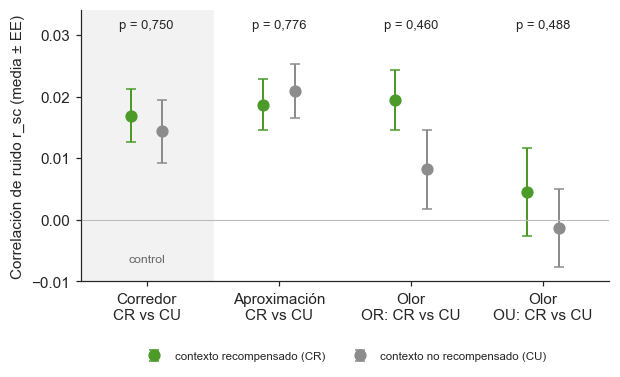

In [27]:
fig, ax = plt.subplots(figsize=(6.2, 3.2))
xs = np.arange(len(COMPARACIONES))
for i, (clave, o) in enumerate(RES4.items()):
    for dx, r, col, lab in [(-0.12, o["r_cr"][o["ok"]], VERDE_CR, "contexto recompensado (CR)"),
                            (0.12, o["r_cu"][o["ok"]], GRIS_CU, "contexto no recompensado (CU)")]:
        ax.errorbar(i + dx, r.mean(), yerr=r.std(ddof=1) / np.sqrt(len(r)), fmt="o", color=col, ms=7, capsize=3,
                    lw=1.3, label=lab if i == 0 else None)
    ax.text(i, 0.031, p_txt(o["p"]), ha="center", fontsize=8.5, fontweight="bold" if o["p"] < 0.05 else "normal")
ax.axhline(0, color="#BBBBBB", lw=0.7)
ax.axvspan(-0.5, 0.5, color="#F2F2F2", zorder=0)
ax.set_xticks(xs)
ax.set_xticklabels([f"{e}\n{c}" for e, c, _ in COMPARACIONES])
ax.set_xlim(-0.5, len(xs) - 0.5)
ax.set_ylabel("Correlación de ruido r_sc (media ± EE)")
ax.text(0, ax.get_ylim()[0] + 0.002, "control", ha="center", fontsize=8, color=GRIS, va="bottom")
ax.set_ylim(-0.01, 0.034)
ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
guardar(fig, "parte4/rsc_por_contexto.png")
plt.show()

### IV.1 · Controles

1. **Distribución nula por permutación** (arriba): dónde cae el Δ observado respecto de 1000 permutaciones de contexto.
2. **Tasa de disparo**: r_sc crece con la tasa (de la Rocha et al. 2007). Si un contexto tiene más actividad, r_sc podría
   subir sólo por eso. Lo controlamos de dos formas: Δ ajustado por la tasa geométrica del par (regresión con la tasa
   como covariable, también testeado por permutación) y Δ dentro de cuartiles de tasa.

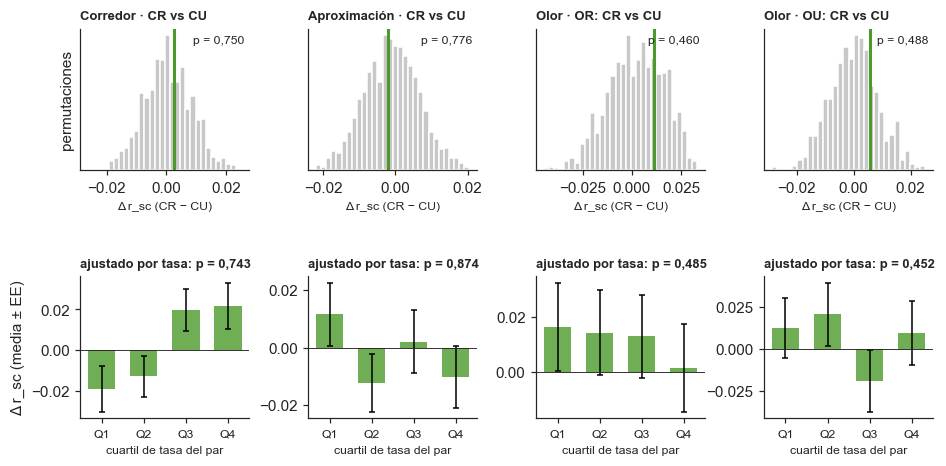

In [28]:
fig, axs = plt.subplots(2, 4, figsize=(10, 4.6), gridspec_kw=dict(hspace=0.75, wspace=0.35))
for j, (clave, o) in enumerate(RES4.items()):
    ax = axs[0, j]
    ax.hist(o["nulo"], bins=30, color="#C8C8C8", edgecolor="white")
    ax.axvline(o["delta"], color=VERDE_CR, lw=2)
    ax.set_title(f"{clave[0]} · {clave[1]}", fontsize=8.5)
    ax.set_xlabel("Δ r_sc (CR − CU)", fontsize=8)
    ax.text(0.97, 0.95, p_txt(o["p"]), transform=ax.transAxes, ha="right", va="top", fontsize=8)
    ax.set_yticks([])
    ax = axs[1, j]
    gm = np.sqrt(o["g_cr"] * o["g_cu"])[o["ok"]]
    d = (o["r_cr"] - o["r_cu"])[o["ok"]]
    q = pd.qcut(gm, 4, labels=False)
    m_ = [d[q == k].mean() for k in range(4)]
    e_ = [d[q == k].std(ddof=1) / np.sqrt((q == k).sum()) for k in range(4)]
    ax.bar(range(4), m_, yerr=e_, color=VERDE_CR, alpha=0.8, width=0.65, error_kw=dict(lw=1, capsize=2))
    ax.axhline(0, color=TINTA, lw=0.6)
    ax.set_xticks(range(4)); ax.set_xticklabels(["Q1", "Q2", "Q3", "Q4"], fontsize=8)
    ax.set_xlabel("cuartil de tasa del par", fontsize=8)
    ax.set_title(f"ajustado por tasa: {p_txt(o['p_aj'])}", fontsize=8.5)
axs[0, 0].set_ylabel("permutaciones")
axs[1, 0].set_ylabel("Δ r_sc (media ± EE)")
guardar(fig, "parte4/rsc_controles.png")
plt.show()

### IV.2 · Ensambles: ¿se coordinan más las neuronas que responden parecido?

- **Semejanza de respuesta (correlación de señal)**: correlación entre los PSTH promedio de dos neuronas, concatenando los
  cuatro tipos de ensayo con olor (−0,5 a 1,5 s desde la inhalación). Alta = responden a lo mismo y con el mismo curso temporal.
- **Acoplamiento**: r_sc de la Parte III (todos los ensayos con olor, 0–1 s) e interacción fina en el CCG (Parte III.b).
- **Test de Mantel**: la correlación entre dos matrices de pares no se puede testear como si los pares fueran
  independientes (cada neurona participa en 43 pares). Se permutan las etiquetas de las neuronas en una de las matrices
  (1000 veces) y se recalcula la correlación de Spearman.
- **Puente con IV.1**: ¿el Δ r_sc por contexto depende de la semejanza de respuesta del par?

In [29]:
tc = TC["inhalacion"]
vent = (tc >= -0.5) & (tc <= 1.5)
SENAL = np.corrcoef(np.concatenate([POB["inhalacion"][k][:, vent] for k in TIPOS_OLOR], axis=1))
sig_par = SENAL[IA, IB]
rsc_par = RSC[IA, IB]


def mantel(M1, M2, n_perm=N_PERM):
    iu = (IA, IB)
    obs_ = stats.spearmanr(M1[iu], M2[iu], nan_policy="omit").statistic
    cnt = 0
    for _ in range(n_perm):
        p = RNG.permutation(M1.shape[0])
        cnt += abs(stats.spearmanr(M1[p][:, p][iu], M2[iu], nan_policy="omit").statistic) >= abs(obs_)
    return obs_, (cnt + 1) / (n_perm + 1)


rho_m, p_m = mantel(SENAL, RSC)
inter = pares_ok.significativo.values
q_sig = pd.qcut(sig_par, 4, labels=False)
frac_int = [inter[q_sig == k].mean() for k in range(4)]
tab = pd.crosstab(q_sig, inter)
p_chi = stats.chi2_contingency(tab)[1]
print(f"Mantel (Spearman) semejanza de respuesta vs r_sc: rho = {rho_m:.2f}, p = {p_m:.3f}")
print("Fracción de pares con interacción fina por cuartil de semejanza:", np.round(frac_int, 3), f"chi2 p = {p_chi:.3g}")
# ¿qué tipo de interacción domina en cada cuartil? (los pares más distintos podrían ser los inhibitorios)
tipo_int = np.select([pares_ok.inh_ab | pares_ok.inh_ba, pares_ok.sincronia, pares_ok.exc_ab | pares_ok.exc_ba],
                     ["inhibitoria", "sincronía", "dirigida"], "ninguna")
COMP_Q = pd.crosstab(q_sig, tipo_int).reindex(columns=["dirigida", "sincronía", "inhibitoria"], fill_value=0)
COMP_Q.index = ["Q1 distintas", "Q2", "Q3", "Q4 parecidas"]
print(COMP_Q.to_string())

DELTA_Q = {}
for clave in [("Aproximación", "CR vs CU"), ("Olor", "OR: CR vs CU")]:
    o = RES4[clave]
    d = (o["r_cr"] - o["r_cu"])
    ok = o["ok"]
    rho_d = stats.spearmanr(sig_par[ok], d[ok]).statistic
    # test de Mantel: permuto las etiquetas de neurona de la matriz de semejanza
    cnt = 0
    for _ in range(N_PERM):
        p = RNG.permutation(SENAL.shape[0])
        cnt += abs(stats.spearmanr(SENAL[p][:, p][IA[ok], IB[ok]], d[ok]).statistic) >= abs(rho_d)
    DELTA_Q[clave] = dict(m=[d[ok][q_sig[ok] == k].mean() for k in range(4)],
                          e=[d[ok][q_sig[ok] == k].std(ddof=1) / np.sqrt((q_sig[ok] == k).sum()) for k in range(4)],
                          rho=rho_d, p=(cnt + 1) / (N_PERM + 1))
    print(f"Δ r_sc {clave[0]} {clave[1]} vs semejanza: rho = {rho_d:.2f}, p (Mantel) = {DELTA_Q[clave]['p']:.3f}")

Mantel (Spearman) semejanza de respuesta vs r_sc: rho = 0.13, p = 0.001
Fracción de pares con interacción fina por cuartil de semejanza: [0.162 0.115 0.115 0.205] chi2 p = 0.0163
col_0         dirigida  sincronía  inhibitoria
Q1 distintas        12         10           16
Q2                  15          7            5
Q3                  14          8            5
Q4 parecidas        21         14           13


Δ r_sc Aproximación CR vs CU vs semejanza: rho = 0.08, p (Mantel) = 0.015


Δ r_sc Olor OR: CR vs CU vs semejanza: rho = -0.07, p (Mantel) = 0.032


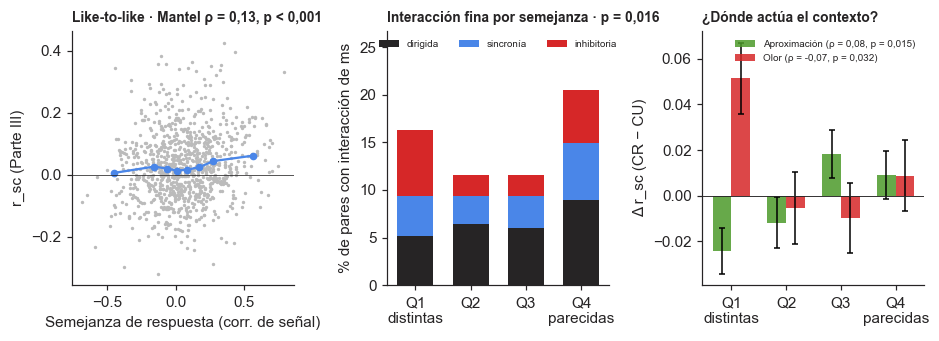

In [30]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3.0), gridspec_kw=dict(wspace=0.42))
ax = axs[0]
ax.scatter(sig_par, rsc_par, s=5, color="#BBBBBB", lw=0, rasterized=True)
bins_s = np.quantile(sig_par, np.linspace(0, 1, 9))
cen = [(bins_s[k] + bins_s[k + 1]) / 2 for k in range(8)]
med = [np.nanmean(rsc_par[(sig_par >= bins_s[k]) & (sig_par <= bins_s[k + 1])]) for k in range(8)]
ax.plot(cen, med, "o-", color=ACENTO, lw=1.5, ms=4)
ax.axhline(0, color=TINTA, lw=0.5)
ax.set_xlabel("Semejanza de respuesta (corr. de señal)")
ax.set_ylabel("r_sc (Parte III)")
ax.set_title(f"Like-to-like · Mantel ρ = {coma_py(rho_m, 2)}, {p_txt(p_m)}", fontsize=9)
ax = axs[1]
n_q = pd.Series(q_sig).value_counts().sort_index().values
abajo = np.zeros(4)
for tipo, col in [("dirigida", TINTA), ("sincronía", ACENTO), ("inhibitoria", "#D62728")]:
    v = 100 * COMP_Q[tipo].values / n_q
    ax.bar(range(4), v, bottom=abajo, color=col, width=0.65, label=tipo)
    abajo += v
ax.set_xticks(range(4)); ax.set_xticklabels(["Q1\ndistintas", "Q2", "Q3", "Q4\nparecidas"])
ax.set_ylabel("% de pares con interacción de ms")
ax.legend(fontsize=6.5, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.0))
ax.set_ylim(0, max(abajo) * 1.3)
ax.set_title(f"Interacción fina por semejanza · {p_txt(p_chi)}", fontsize=9)
ax = axs[2]
for dx, (clave, col) in zip([-0.17, 0.17], [(("Aproximación", "CR vs CU"), VERDE_CR), (("Olor", "OR: CR vs CU"), "#D62728")]):
    dq = DELTA_Q[clave]
    ax.bar(np.arange(4) + dx, dq["m"], yerr=dq["e"], width=0.34, color=col, alpha=0.85,
           error_kw=dict(lw=1, capsize=2), label=f"{clave[0]} (ρ = {coma_py(dq['rho'], 2)}, {p_txt(dq['p'])})")
ax.axhline(0, color=TINTA, lw=0.6)
ax.set_xticks(range(4)); ax.set_xticklabels(["Q1\ndistintas", "Q2", "Q3", "Q4\nparecidas"])
ax.set_ylabel("Δ r_sc (CR − CU)")
ax.set_title("¿Dónde actúa el contexto?", fontsize=9)
ax.legend(fontsize=6.5, loc="upper right")
guardar(fig, "parte4/ensambles_semejanza.png")
plt.show()

### Resumen de la Parte IV (primera mitad) y lo que sigue

Los números se guardan en `figuras/resumen_parte4.json` (los usa la presentación). Lo que falta (IV.3–IV.6) está
detallado en `HANDOFF_parte_IV.md`, con las variables de este notebook que conviene reutilizar.

In [31]:
res4 = {f"{e} | {c}": dict(n_cr=o["n_cr"], n_cu=o["n_cu"], rsc_cr=float(np.mean(o["r_cr"][o["ok"]])),
                           rsc_cu=float(np.mean(o["r_cu"][o["ok"]])), delta=float(o["delta"]), p=float(o["p"]),
                           delta_aj=float(o["delta_aj"]), p_aj=float(o["p_aj"]),
                           tasa_cr=float(o["tasa_cr"]), tasa_cu=float(o["tasa_cu"]), mde=float(o["mde"]))
        for (e, c), o in RES4.items()}
res4["mantel_rho"], res4["mantel_p"] = float(rho_m), float(p_m)
res4["frac_interaccion_por_cuartil"] = [float(x) for x in frac_int]
res4["p_chi_interaccion"] = float(p_chi)
res4["composicion_por_cuartil"] = {q: {k: int(v) for k, v in fila.items()} for q, fila in COMP_Q.iterrows()}
res4["delta_vs_semejanza"] = {f"{k[0]} | {k[1]}": dict(rho=float(v["rho"]), p=float(v["p"])) for k, v in DELTA_Q.items()}
res4["n_pares"] = int(len(pares_ok))
(FIG / "resumen_parte4.json").write_text(pd.Series(res4, dtype=object).to_json(force_ascii=False, indent=1), encoding="utf-8")
pd.Series(res4, dtype=object)

Corredor | CR vs CU             {'n_cr': 100, 'n_cu': 75, 'rsc_cr': 0.01692416...
Aproximación | CR vs CU         {'n_cr': 100, 'n_cu': 75, 'rsc_cr': 0.01870640...
Olor | OR: CR vs CU             {'n_cr': 63, 'n_cu': 30, 'rsc_cr': 0.019410186...
Olor | OU: CR vs CU             {'n_cr': 24, 'n_cu': 33, 'rsc_cr': 0.004501771...
mantel_rho                                                               0.130885
mantel_p                                                                 0.000999
frac_interaccion_por_cuartil    [0.1623931623931624, 0.11538461538461539, 0.11...
p_chi_interaccion                                                        0.016326
composicion_por_cuartil         {'Q1 distintas': {'dirigida': 12, 'sincronía':...
delta_vs_semejanza              {'Aproximación | CR vs CU': {'rho': 0.08311604...
n_pares                                                                       936
dtype: object